# Proyecto final
**Análisis descriptivo de accidentes de tránsito en Hermosillo: tendencias y comparativas nacionales**




**Etapas: Métricas de Calidad de los Datos, Análisis Descriptivo y Preprocesamiento**

Nombre: _Karla María Monroy Álvarez_
Matrícula: _263164_

Fecha: 10/10/2025

## 1) Introducción
- **Descripción breve del problema que se pretende abordar.**

    Los accidentes de tránsito son una de las principales causas de lesiones y muertes en las zonas urbanas de México. Hermosillo, como una de las ciudades con mayor crecimiento vehicular en el país, presenta un número significativo de incidentes viales cada año. Sin embargo, no existe un análisis detallado que compare sus patrones de accidentes con los del resto del país ni que identifique los factores más relevantes que los generan.

    Este proyecto busca analizar los accidentes de tránsito en Hermosillo durante 2024 y compararlos con el panorama nacional para encontrar patrones en tipos de accidentes, vehículos involucrados, víctimas, horarios críticos y causas más frecuentes.

- **Objetivo general del proyecto y objetivos específicos.**

    - **Objetivo general**

        Analizar los accidentes de tránsito registrados en Hermosillo durante 2024 y compararlos con los datos del resto de México, para identificar patrones y factores de riesgo que permitan proponer medidas de prevención y seguridad vial.

    - **Objetivos específicos**

        * Determinar cuántos accidentes ocurrieron en Hermosillo en 2024 y compararlos con otras ciudades del país.

        * Identificar los tipos de accidentes más frecuentes y su distribución.

        * Cuantificar lesionados y fallecidos según tipo de accidente.

        * Analizar qué días de la semana y horas del día presentan mayor número de accidentes.

        * Determinar qué tipos de vehículos están más involucrados y generan más víctimas.

        * Identificar las principales causas de accidentes en Hermosillo.

- Contexto del dataset en relación con el problema planteado.
    
    El análisis se basa en el conjunto de datos “Accidentes de Tránsito Terrestre en Zonas Urbanas y Suburbanas (ATUS)” publicado por INEGI, que contiene información nacional de accidentes registrados por las autoridades de tránsito.

    * Formato: CSV descargable de acceso público.

    * Cobertura: Todos los estados y municipios de México.

    * Variables relevantes:

        * Localización (estado, municipio).

        * Fecha y hora del accidente.

        * Tipo de accidente y causas.

        * Tipo de vehículo involucrado.

        * Número de lesionados y fallecidos.

        * Tamaño: Para 2024 el dataset tiene 390,627 registros a nivel nacional y 11,991 registros para Hermosillo.

    Este dataset es suficientemente grande y representativo para responder las preguntas planteadas y no contiene datos personales identificables, por lo que puede utilizarse de manera legal y ética para fines de análisis estadístico.

## 2) Descripción del dataset
- Fuente de los datos.

    El conjunto de datos proviene del Instituto Nacional de Estadística y Geografía (INEGI), específicamente del sistema “Accidentes de Tránsito Terrestre en Zonas Urbanas y Suburbanas (ATUS)”. Es un dataset público, descargable en formato CSV desde la página oficial del INEGI.

- Número de registros y variables.
    - Para el año 2024 el dataset contiene:

        - 390,627 registros a nivel nacional.

        - 11,991 registros correspondientes a Hermosillo, Sonora.

        - 45 variables (columnas) que describen características del accidente: fecha, hora, tipo de accidente, causas, tipo de vehículos involucrados y víctimas.

- Variables principales de interés.

    - Para responder las preguntas del proyecto se usarán principalmente:

        - Localización: ID_ENTIDAD, ID_MUNICIPIO.

        - Fecha y hora: ANIO, MES, ID_DIA, ID_HORA.

        - Características del accidente: TIPACCID (tipo de accidente), CAUSAACCI (causa del accidente), CLASACC (clasificación del accidente).

        - Vehículos involucrados: AUTOMOVIL, MOTOCICLET, BICICLETA, CAMION, etc.

        - Víctimas: CONDMUERTO, CONDHERIDO, PASAMUERTO, PASAHERIDO, PEATMUERTO, PEATHERIDO, etc.

- Limitaciones del dataset.

    - Registro administrativo: solo incluye accidentes reportados oficialmente por autoridades de tránsito, no todos los ocurridos.

    - Desfase temporal: algunos datos se publican con retraso respecto al año en curso.

    - Información resumida: no contiene datos personales ni circunstancias detalladas (por ejemplo, condiciones climáticas o estado de la infraestructura).

    - Codificación de valores: varias variables usan códigos numéricos que requieren los catálogos de INEGI para interpretarse correctamente.

In [186]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [187]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/Unidad02/atus_anual_2024.csv', encoding='utf-8')

print("Dimensiones:", df.shape)
df.head()

Dimensiones: (390627, 45)


,COBERTURA,ID_ENTIDAD,ID_MUNICIPIO,ANIO,MES,ID_HORA,ID_MINUTO,ID_DIA,DIASEMANA,URBANA,...,PEATMUERTO,PEATHERIDO,CICLMUERTO,CICLHERIDO,OTROMUERTO,OTROHERIDO,NEMUERTO,NEHERIDO,CLASACC,ESTATUS
0,Municipal,1,1,2024,1,2,25,1,lunes,Accidente en intersección,...,0,0,0,0,0,0,0,0,Sólo daños,Cifras Corregidas
1,Municipal,1,1,2024,1,3,40,1,lunes,Accidente en intersección,...,0,0,0,0,0,0,0,0,Sólo daños,Cifras Corregidas
2,Municipal,1,1,2024,1,4,37,1,lunes,Accidente en intersección,...,0,1,0,0,0,0,0,0,No fatal,Cifras Corregidas
3,Municipal,1,1,2024,1,5,0,1,lunes,Accidente en intersección,...,0,0,0,0,0,0,0,0,Sólo daños,Cifras Corregidas
4,Municipal,1,1,2024,1,6,45,1,lunes,Accidente en intersección,...,0,0,0,0,0,0,0,0,Sólo daños,Cifras Corregidas


In [188]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 390627 entries, 0 to 390626
Data columns (total 45 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   COBERTURA     390627 non-null  object
 1   ID_ENTIDAD    390627 non-null  int64 
 2   ID_MUNICIPIO  390627 non-null  int64 
 3   ANIO          390627 non-null  int64 
 4   MES           390627 non-null  int64 
 5   ID_HORA       390627 non-null  int64 
 6   ID_MINUTO     390627 non-null  int64 
 7   ID_DIA        390627 non-null  int64 
 8   DIASEMANA     390627 non-null  object
 9   URBANA        390627 non-null  object
 10  SUBURBANA     390627 non-null  object
 11  TIPACCID      390627 non-null  object
 12  AUTOMOVIL     390627 non-null  int64 
 13  CAMPASAJ      390627 non-null  int64 
 14  MICROBUS      390627 non-null  int64 
 15  PASCAMION     390627 non-null  int64 
 16  OMNIBUS       390627 non-null  int64 
 17  TRANVIA       390627 non-null  int64 
 18  CAMIONETA     390627 non

In [189]:
# Iterar sobre cada columna del DataFrame e imprimir sus valores únicos
for columna in df.columns:
    valores_unicos = df[columna].unique()
    print(f"Valores únicos para la columna '{columna}':")
    print(valores_unicos)
    print("-" * 30) # Separador para mejor legibilidad

Valores únicos para la columna 'COBERTURA':
['Municipal']
------------------------------
Valores únicos para la columna 'ID_ENTIDAD':
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32]
------------------------------
Valores únicos para la columna 'ID_MUNICIPIO':
[  1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18
  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36
  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54
  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72
  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90
  91  92  93  94  96  97  98  99 100 101 102 103 104 105 106 107 108 109
 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125  95 126
 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143 144
 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161 162
 163 164 165 166 167 168 169 170

## 3) Preguntas de análisis descriptivo
- Formular al menos tres preguntas directamente relacionadas con el problema del proyecto.

Ejemplos:
- ¿Cuál es la distribución de la variable objetivo?
- ¿Qué diferencias existen entre categorías relevantes (ejemplo: clientes con y sin deuda, hombres y mujeres, productos por región)?
- ¿Existen valores atípicos que distorsionen la interpretación del conjunto de datos?

**Cantidad y distribución de accidentes**

   - ¿Cuántos accidentes ocurrieron en Hermosillo en 2024 y cómo se compara con el promedio nacional y con otras ciudades del país?

   - ¿Cómo se distribuyen los accidentes a lo largo de los meses, días de la semana y horas del día?

**Tipos de accidentes y víctimas**

   - ¿Qué tipo de accidente ocurre con mayor frecuencia en Hermosillo y en México?

   - ¿Cuántos lesionados y fallecidos hubo por tipo de accidente en Hermosillo?

   - ¿Qué tipos de vehículos están más involucrados en accidentes y generan más víctimas?

**Causas y factores de riesgo**

   - ¿Cuáles son las principales causas de accidentes en Hermosillo y cómo se comparan con las causas a nivel nacional?

   - ¿Existen diferencias en los patrones de accidentes (tipo, hora, víctimas) según la causa reportada?

**Análisis de valores atípicos y concentraciones**

   - ¿Hay días/horas puntuales donde los accidentes se disparan anormalmente (picos)?

   - ¿Qué municipios o zonas concentran la mayor cantidad de accidentes graves en Sonora?

## 4) Métricas de calidad de los datos

In [190]:
# Valores faltantes
print("Valores faltantes por columna")
print(df.isnull().sum())

# Duplicados
print("\n")
print("Datos duplicados por columnas")
print(df.duplicated().sum())

# Tipos de datos
print("\n")
print("Tipo de datos por columnas")
print(df.dtypes)

Valores faltantes por columna
COBERTURA       0
ID_ENTIDAD      0
ID_MUNICIPIO    0
ANIO            0
MES             0
ID_HORA         0
ID_MINUTO       0
ID_DIA          0
DIASEMANA       0
URBANA          0
SUBURBANA       0
TIPACCID        0
AUTOMOVIL       0
CAMPASAJ        0
MICROBUS        0
PASCAMION       0
OMNIBUS         0
TRANVIA         0
CAMIONETA       0
CAMION          0
TRACTOR         0
FERROCARRI      0
MOTOCICLET      0
BICICLETA       0
OTROVEHIC       0
CAUSAACCI       0
CAPAROD         0
SEXO            0
ALIENTO         0
CINTURON        0
ID_EDAD         0
CONDMUERTO      0
CONDHERIDO      0
PASAMUERTO      0
PASAHERIDO      0
PEATMUERTO      0
PEATHERIDO      0
CICLMUERTO      0
CICLHERIDO      0
OTROMUERTO      0
OTROHERIDO      0
NEMUERTO        0
NEHERIDO        0
CLASACC         0
ESTATUS         0
dtype: int64


Datos duplicados por columnas
871


Tipo de datos por columnas
COBERTURA       object
ID_ENTIDAD       int64
ID_MUNICIPIO     int64
ANIO         

## 5) Limpieza de los datos

### Datos duplicados

Como veo que no hay datos faltantes en ninguna columna, omito este paso en la limpieza.

Primero, comenzaré buscando datos duplicados en el dataset

In [191]:
# Identificar las filas duplicadas
filas_duplicadas = df[df.duplicated(keep=False)]

# Mostrar las filas duplicadas
print("Filas duplicadas:")
display(filas_duplicadas.head(50))

# Opcional: Contar el número de filas duplicadas
print("\nNúmero total de filas duplicadas:", filas_duplicadas.shape[0])

Filas duplicadas:


,COBERTURA,ID_ENTIDAD,ID_MUNICIPIO,ANIO,MES,ID_HORA,ID_MINUTO,ID_DIA,DIASEMANA,URBANA,...,PEATMUERTO,PEATHERIDO,CICLMUERTO,CICLHERIDO,OTROMUERTO,OTROHERIDO,NEMUERTO,NEHERIDO,CLASACC,ESTATUS
4073,Municipal,1,7,2024,9,13,25,30,lunes,Accidente en no intersección,...,0,0,0,0,0,0,0,0,Sólo daños,Cifras Definitivas
4074,Municipal,1,7,2024,9,13,25,30,lunes,Accidente en no intersección,...,0,0,0,0,0,0,0,0,Sólo daños,Cifras Definitivas
4377,Municipal,2,1,2024,1,10,22,9,Martes,Accidente en intersección,...,0,0,0,0,0,0,0,0,Sólo daños,Cifras Definitivas
4378,Municipal,2,1,2024,1,10,22,9,Martes,Accidente en intersección,...,0,0,0,0,0,0,0,0,Sólo daños,Cifras Definitivas
4474,Municipal,2,1,2024,1,15,25,18,Jueves,Accidente en intersección,...,0,0,0,0,0,0,0,0,Sólo daños,Cifras Definitivas
4475,Municipal,2,1,2024,1,15,25,18,Jueves,Accidente en intersección,...,0,0,0,0,0,0,0,0,Sólo daños,Cifras Definitivas
4697,Municipal,2,1,2024,2,17,40,6,Martes,Accidente en intersección,...,0,0,0,0,0,0,0,0,Sólo daños,Cifras Definitivas
4698,Municipal,2,1,2024,2,17,40,6,Martes,Accidente en intersección,...,0,0,0,0,0,0,0,0,Sólo daños,Cifras Definitivas
5124,Municipal,2,1,2024,3,5,22,11,lunes,Accidente en intersección,...,0,0,0,0,0,0,0,0,Sólo daños,Cifras Definitivas
5125,Municipal,2,1,2024,3,5,22,11,lunes,Accidente en intersección,...,0,0,0,0,0,0,0,0,Sólo daños,Cifras Definitivas



Número total de filas duplicadas: 1678


Hay un total de 1678 registros duplicados. Me interesa quedarme con solo con la primera coincidencia de los duplicados por lo que elimino el resto.

In [192]:
print("Filas antes de eliminar duplicados:", df.shape[0])

# Conservar la primera fila de cada grupo duplicado
df = df.drop_duplicates(keep='first')

print("Filas después de eliminar duplicados:", df.shape[0])

Filas antes de eliminar duplicados: 390627
Filas después de eliminar duplicados: 389756


In [193]:
filas_duplicadas = df[df.duplicated(keep=False)]
filas_duplicadas

,COBERTURA,ID_ENTIDAD,ID_MUNICIPIO,ANIO,MES,ID_HORA,ID_MINUTO,ID_DIA,DIASEMANA,URBANA,...,PEATMUERTO,PEATHERIDO,CICLMUERTO,CICLHERIDO,OTROMUERTO,OTROHERIDO,NEMUERTO,NEHERIDO,CLASACC,ESTATUS


### Ajustar tipo de datos

Previamente identifiqué que muchas columnas que deberían ser categóricas aparecían como object (string). Para un mejor control de los datos es necesario convertirlas a tipo categórico.

A continuación voy a proceder a convertir las columnas que lo requieran a tipo categórico.

In [194]:
# Columnas a convertir a tipo categórico
columnas_categoricas = [
    'COBERTURA',
    'ID_ENTIDAD',
    'ID_MUNICIPIO',
    'ID_DIA',
    'ID_HORA',
    'ID_MINUTO',
    'MES',
    'DIASEMANA',
    'URBANA',
    'SUBURBANA',
    'TIPACCID',
    'CAUSAACCI',
    'CAPAROD',
    'SEXO',
    'ALIENTO',
    'CINTURON',
    'CLASACC',
    'ESTATUS'
]

# Convertir las columnas a tipo categórico en el DataFrame principal (df)
for col in columnas_categoricas:
    if col in df.columns:
        df[col] = df[col].astype('category')

# Verificar los tipos de datos después de la conversión en df
print("Tipos de datos después de la conversión en df:")
display(df[columnas_categoricas].dtypes)

Tipos de datos después de la conversión en df:


,0
COBERTURA,category
ID_ENTIDAD,category
ID_MUNICIPIO,category
ID_DIA,category
ID_HORA,category
ID_MINUTO,category
MES,category
DIASEMANA,category
URBANA,category
SUBURBANA,category


## 6) Análisis descriptivo de los datos

### Sub dataframe solo de Estado Sonora Municipio Hermosillo

In [195]:
# Ahora creamos dh_hermosillo a partir del DataFrame df que ya tiene las columnas categóricas convertidas
dh_hermosillo = df[(df['ID_ENTIDAD'] == 26) & (df['ID_MUNICIPIO'] == 30)].copy()

In [196]:
# Eliminar la columna 'CINTURON' del DataFrame dh_hermosillo
dh_hermosillo = dh_hermosillo.drop(columns=['CINTURON'])

### Accidentes por municipio

#### Comparativa nacional por municipio

In [197]:
# Cargar catálogos
df_entidad = pd.read_csv('/content/drive/MyDrive/Unidad02/tc_entidad.csv', encoding='utf-8')
df_municipio = pd.read_csv('/content/drive/MyDrive/Unidad02/tc_municipio.csv', encoding='utf-8')

# Contar número de accidentes por municipio y estado
municipios_mas_accidentes = (
    df.groupby(['ID_ENTIDAD', 'ID_MUNICIPIO'])
      .size()
      .reset_index(name='numero_accidentes')
      .sort_values(by='numero_accidentes', ascending=False)
)
# Merge con nombres de estados
municipios_con_nombres = pd.merge(
    municipios_mas_accidentes,
    df_entidad[['ID_ENTIDAD', 'NOM_ENTIDAD']],
    on='ID_ENTIDAD', how='left'
)

# Merge con nombres de municipios
municipios_con_nombres = pd.merge(
    municipios_con_nombres,
    df_municipio[['ID_ENTIDAD','ID_MUNICIPIO','NOM_MUNICIPIO']],
    on=['ID_ENTIDAD','ID_MUNICIPIO'], how='left'
)


/tmp/ipython-input-4145684339.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(['ID_ENTIDAD', 'ID_MUNICIPIO'])


### Promedio nacional de accidentes y municipios con mayor numero de accidentes

In [198]:
# Calcular el promedio nacional de accidentes por municipio
promedio_nacional_accidentes = df.groupby(['ID_ENTIDAD', 'ID_MUNICIPIO']).size().mean()

print(f"Promedio nacional de accidentes por municipio: {promedio_nacional_accidentes:.2f}")

# Mostrar los 10 municipios con más accidentes y compararlos con el promedio nacional
print("\nComparación del número de accidentes por municipio con el promedio nacional:")
display(municipios_con_nombres[['NOM_ENTIDAD','NOM_MUNICIPIO','numero_accidentes']].head(10))

Promedio nacional de accidentes por municipio: 21.37

Comparación del número de accidentes por municipio con el promedio nacional:


/tmp/ipython-input-52730494.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  promedio_nacional_accidentes = df.groupby(['ID_ENTIDAD', 'ID_MUNICIPIO']).size().mean()


,NOM_ENTIDAD,NOM_MUNICIPIO,numero_accidentes
0,Nuevo León,Monterrey,33506
1,Sonora,Hermosillo,11985
2,Chihuahua,Chihuahua,9724
3,Nuevo León,San Nicolás de los Garza,8906
4,Michoacán de Ocampo,Morelia,7082
5,Puebla,Puebla,6828
6,Nuevo León,San Pedro Garza García,6715
7,Chihuahua,Juárez,6413
8,Durango,Durango,6268
9,Guanajuato,León,6049


### Accidentes por mes

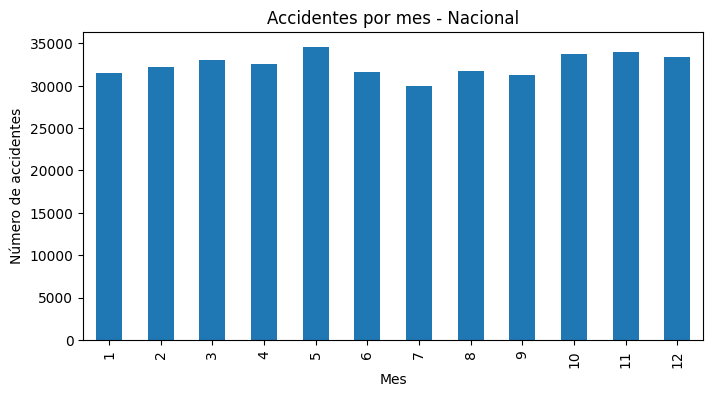

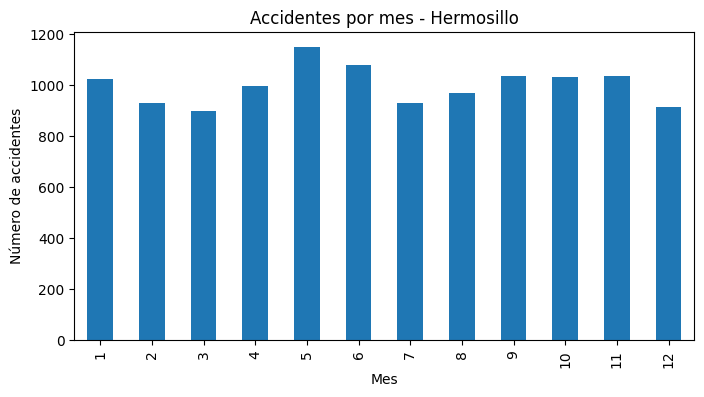

In [199]:
import matplotlib.pyplot as plt

# Nacional
accidentes_mes_nac = df['MES'].value_counts().sort_index()
accidentes_mes_nac.plot(kind='bar', figsize=(8,4), title='Accidentes por mes - Nacional')
plt.xlabel('Mes'); plt.ylabel('Número de accidentes')
plt.show()

# Hermosillo
accidentes_mes_her = dh_hermosillo['MES'].value_counts().sort_index()
accidentes_mes_her.plot(kind='bar', figsize=(8,4), title='Accidentes por mes - Hermosillo')
plt.xlabel('Mes'); plt.ylabel('Número de accidentes')
plt.show()

### Accidentes por hora

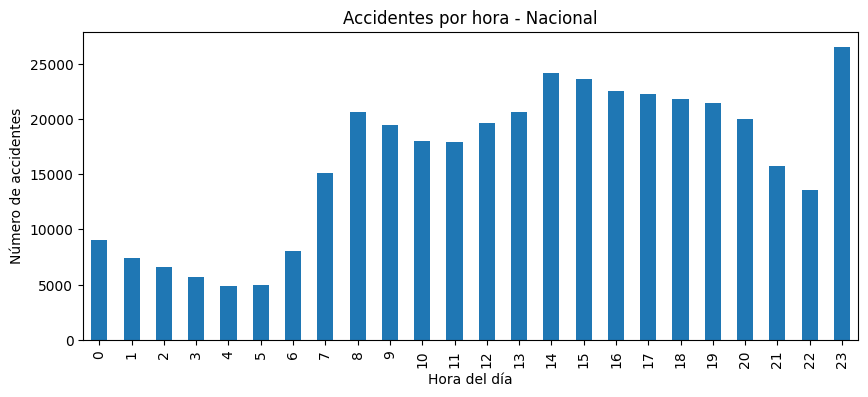

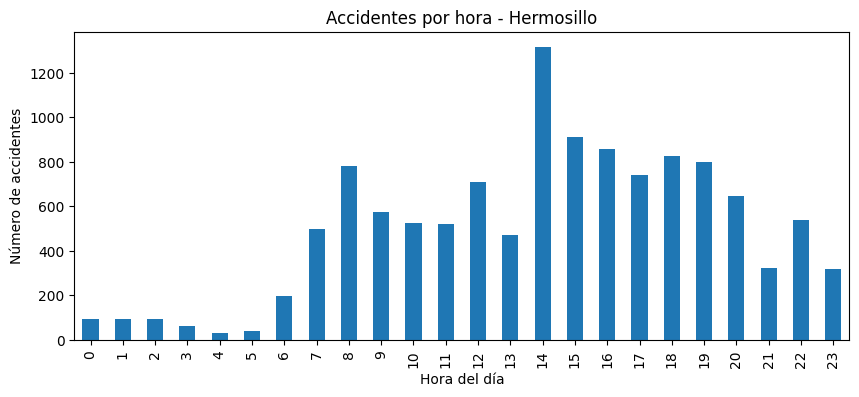

In [200]:
# Nacional
accidentes_hora_nac = df['ID_HORA'].value_counts().sort_index()
accidentes_hora_nac.plot(kind='bar', figsize=(10,4), title='Accidentes por hora - Nacional')
plt.xlabel('Hora del día'); plt.ylabel('Número de accidentes')
plt.show()

# Hermosillo
accidentes_hora_her = dh_hermosillo['ID_HORA'].value_counts().sort_index()
accidentes_hora_her.plot(kind='bar', figsize=(10,4), title='Accidentes por hora - Hermosillo')
plt.xlabel('Hora del día'); plt.ylabel('Número de accidentes')
plt.show()


### Accidentes por día de la semana

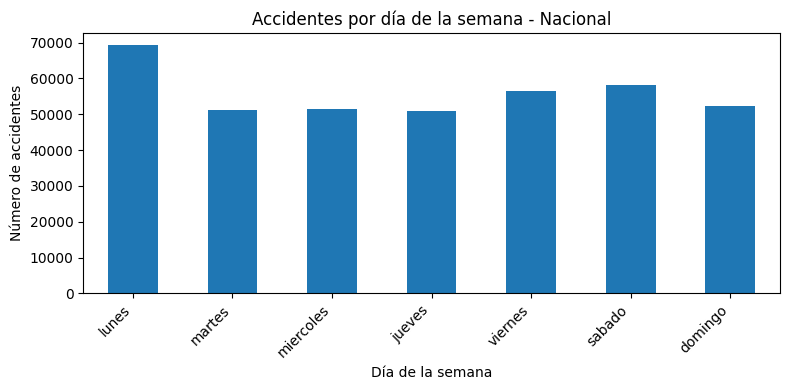

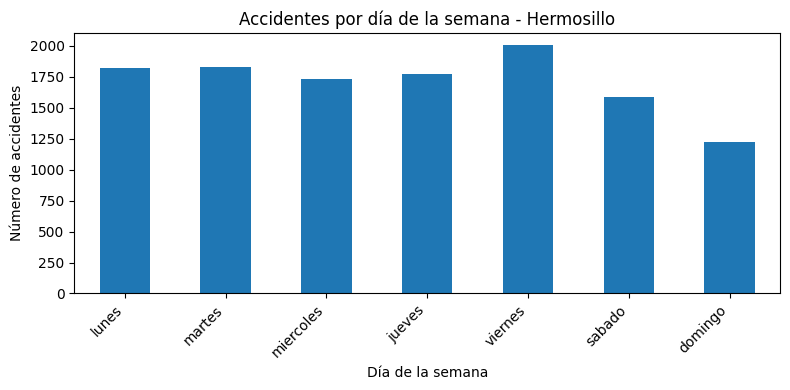

In [201]:
import matplotlib.pyplot as plt

# Estandarizar la capitalización de los días de la semana
df['DIASEMANA'] = df['DIASEMANA'].str.lower()
dh_hermosillo = dh_hermosillo.copy() # Create a copy to avoid SettingWithCopyWarning
dh_hermosillo['DIASEMANA'] = dh_hermosillo['DIASEMANA'].str.lower()

# Nacional
accidentes_dia_semana_nac = df['DIASEMANA'].value_counts()
# Order the days of the week correctly for plotting
dias_ordenados = ['lunes', 'martes', 'miercoles', 'jueves', 'viernes', 'sabado', 'domingo']
accidentes_dia_semana_nac = accidentes_dia_semana_nac.reindex(dias_ordenados)
accidentes_dia_semana_nac.plot(kind='bar', figsize=(8,4), title='Accidentes por día de la semana - Nacional')
plt.xlabel('Día de la semana'); plt.ylabel('Número de accidentes')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Hermosillo
accidentes_dia_semana_her = dh_hermosillo['DIASEMANA'].value_counts()
# Order the days of the week correctly for plotting
accidentes_dia_semana_her = accidentes_dia_semana_her.reindex(dias_ordenados)
accidentes_dia_semana_her.plot(kind='bar', figsize=(8,4), title='Accidentes por día de la semana - Hermosillo')
plt.xlabel('Día de la semana'); plt.ylabel('Número de accidentes')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Tipo de accidente más frecuente

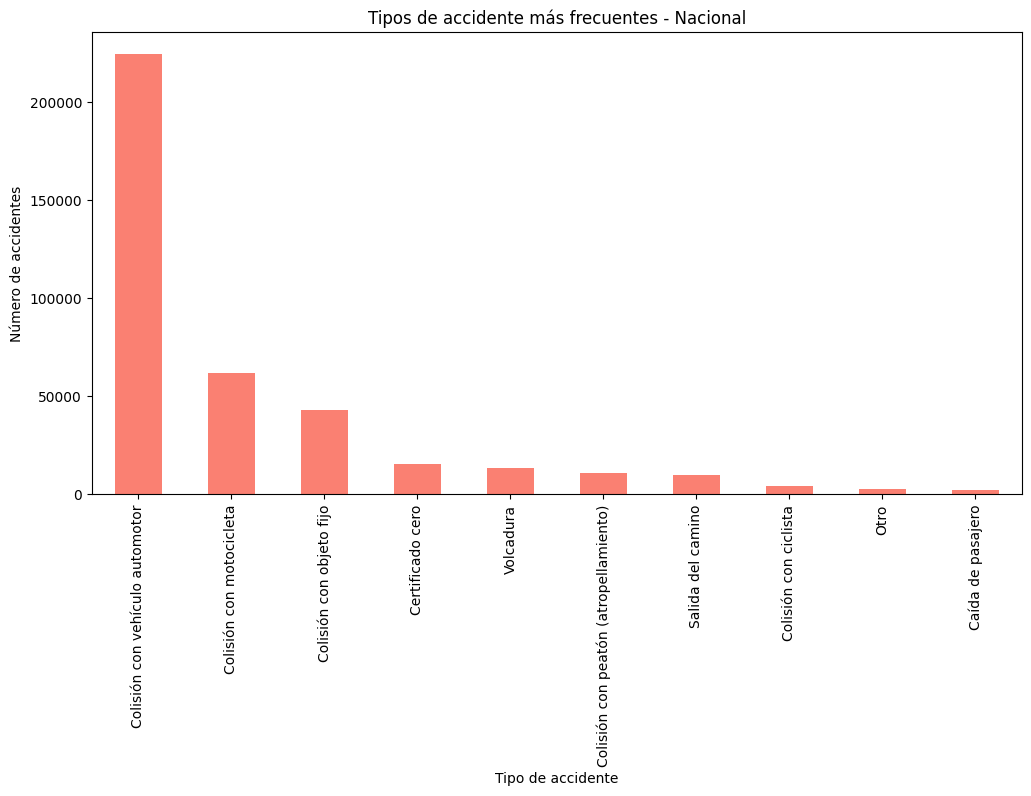

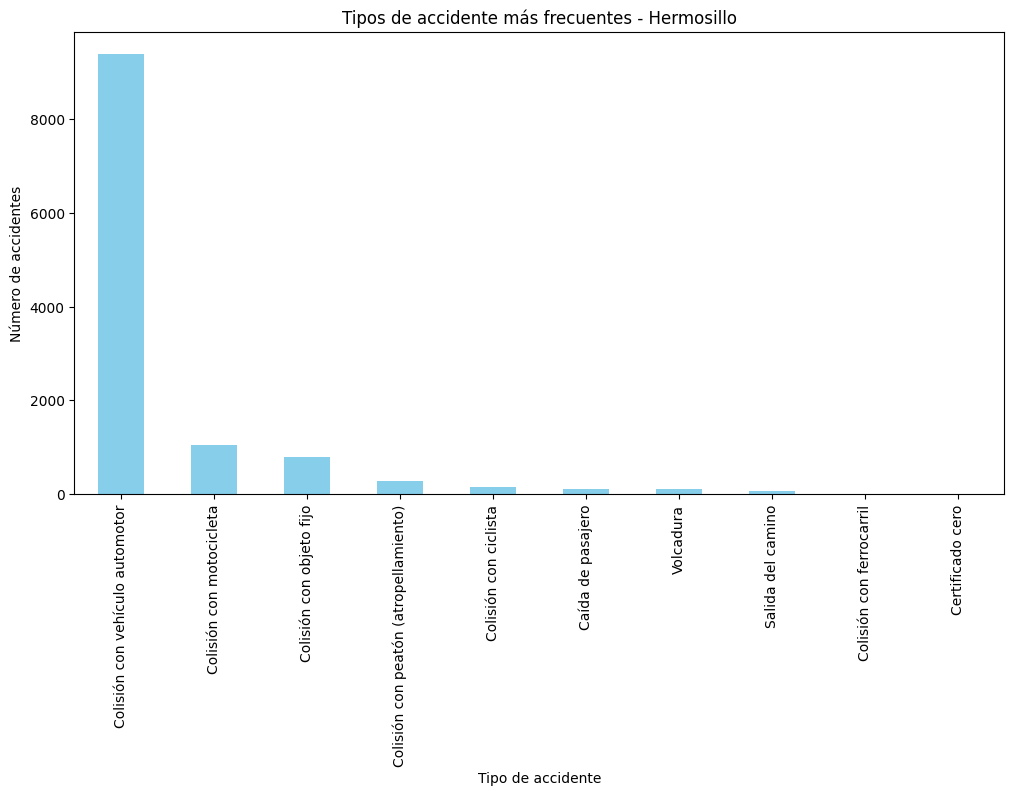

In [202]:
import matplotlib.pyplot as plt

figsize = (12,6)

# Nacional
top10_nacional = df['TIPACCID'].value_counts().head(10)
top10_nacional.plot(
    kind='bar', figsize=figsize, color='salmon', title='Tipos de accidente más frecuentes - Nacional'
)
plt.ylabel('Número de accidentes')
plt.xlabel('Tipo de accidente')
plt.xticks(rotation=90)
plt.show()

# Hermosillo
top10_hermosillo = dh_hermosillo['TIPACCID'].value_counts().head(10)
top10_hermosillo.plot(
    kind='bar', figsize=figsize, color='skyblue', title='Tipos de accidente más frecuentes - Hermosillo'
)
plt.ylabel('Número de accidentes')
plt.xlabel('Tipo de accidente')
plt.xticks(rotation=90)
plt.show()

### Heridos y fallecidos por tipo de accidente

In [203]:
# Columnas de víctimas

#Columna de fallecidos
fallecidos_cols = ['CONDMUERTO', 'PASAMUERTO', 'PEATMUERTO', 'CICLMUERTO', 'OTROMUERTO', 'NEMUERTO']

#Columna de heridos
heridos_cols = ['CONDHERIDO', 'PASAHERIDO', 'PEATHERIDO', 'CICLHERIDO', 'OTROHERIDO', 'NEHERIDO']

# Agrupar por tipo de accidente y sumar fallecidos y heridos por separado
fallecidos_por_tipo_nac = df.groupby('TIPACCID', observed=False)[fallecidos_cols].sum().sum(axis=1) # Sumar a través de las columnas de fallecidos
heridos_por_tipo_nac = df.groupby('TIPACCID', observed=False)[heridos_cols].sum().sum(axis=1) # Sumar a través de las columnas de heridos
fallecidos_por_tipo_herm = dh_hermosillo.groupby('TIPACCID', observed=False)[fallecidos_cols].sum().sum(axis=1) # Sumar a través de las columnas de fallecidos
heridos_por_tipo_herm = dh_hermosillo.groupby('TIPACCID', observed=False)[heridos_cols].sum().sum(axis=1) # Sumar a través de las columnas de heridos


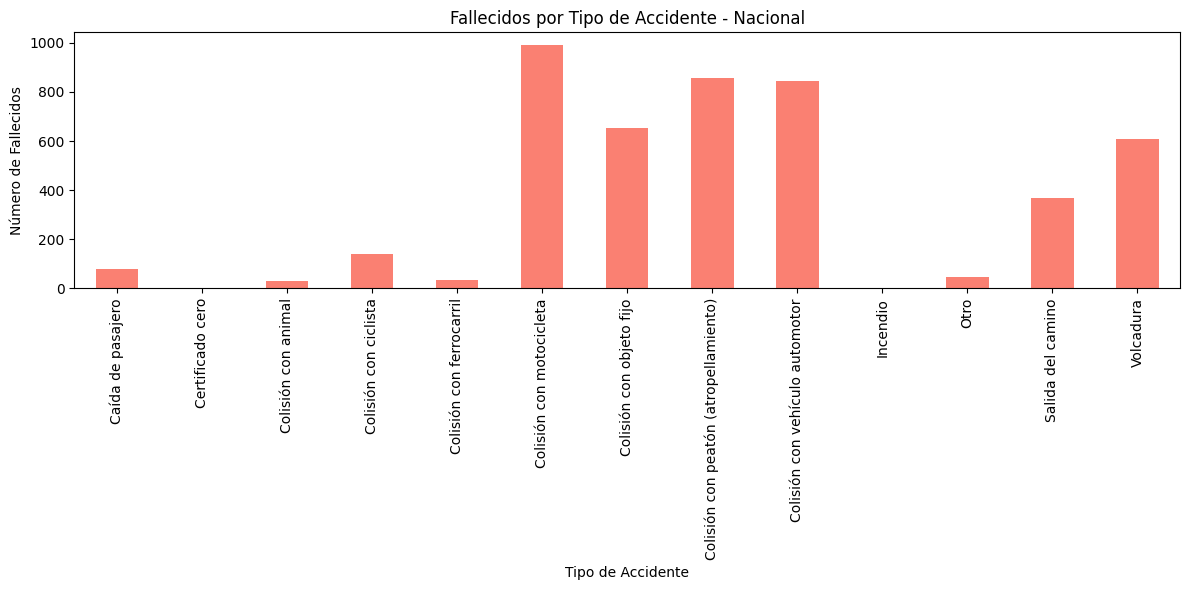

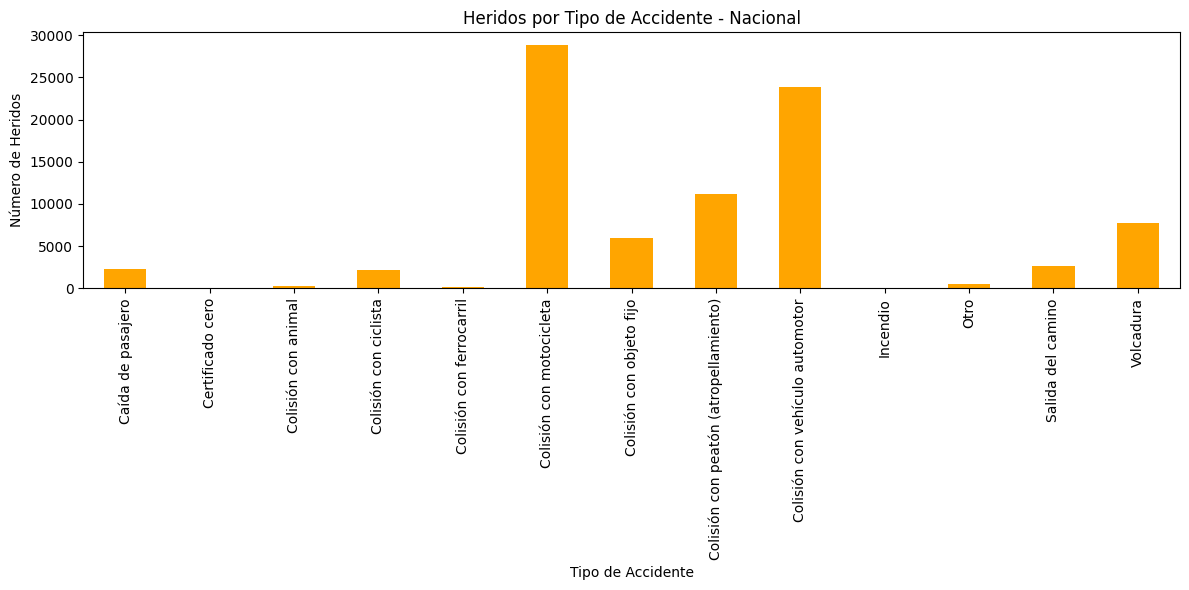

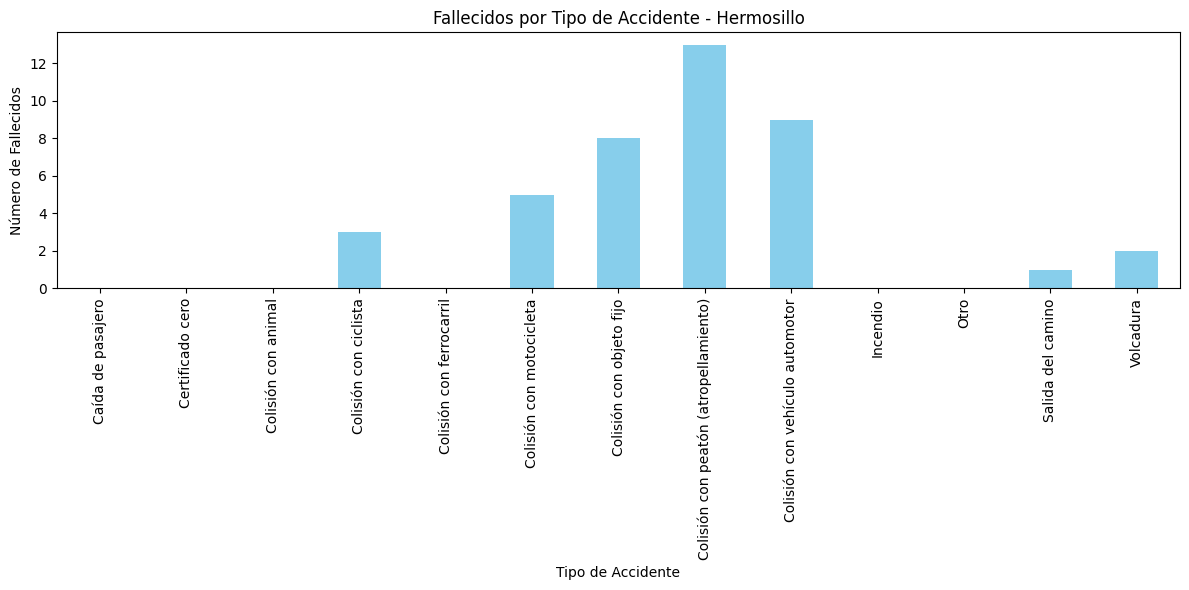

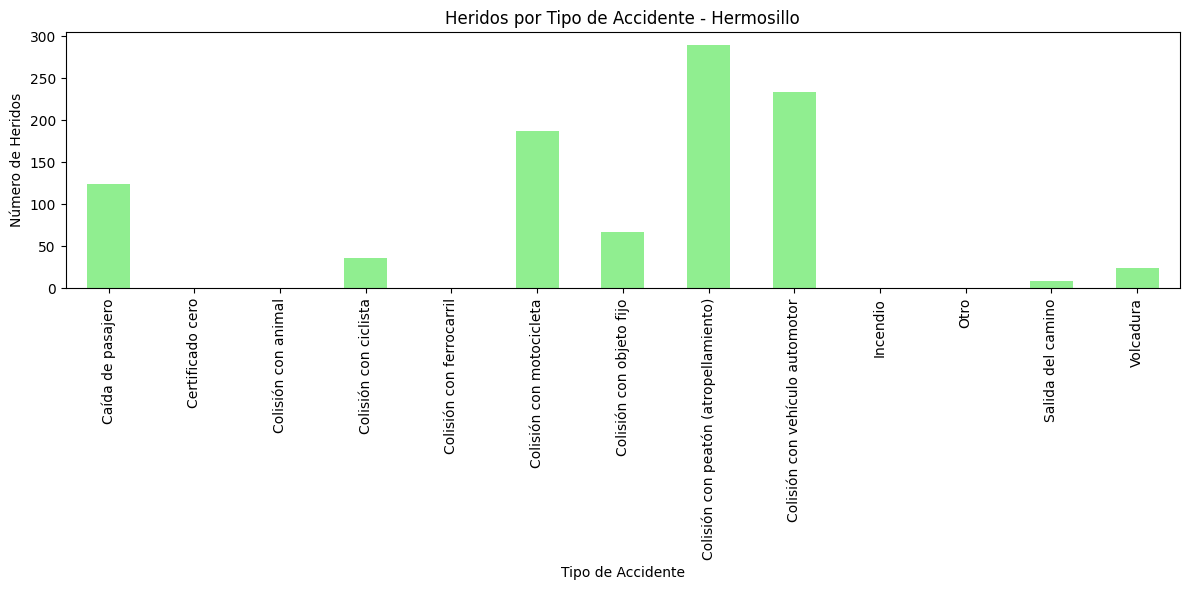

In [204]:
import matplotlib.pyplot as plt
import seaborn as sns

# Gráfico de Fallecidos por tipo de accidente - Nacional
plt.figure(figsize=(12, 6))
fallecidos_por_tipo_nac.plot(kind='bar', color='salmon')
plt.title('Fallecidos por Tipo de Accidente - Nacional')
plt.xlabel('Tipo de Accidente')
plt.ylabel('Número de Fallecidos')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Gráfico de Heridos por tipo de accidente - Nacional
plt.figure(figsize=(12, 6))
heridos_por_tipo_nac.plot(kind='bar', color='orange')
plt.title('Heridos por Tipo de Accidente - Nacional')
plt.xlabel('Tipo de Accidente')
plt.ylabel('Número de Heridos')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Gráfico de Fallecidos por tipo de accidente - Hermosillo
plt.figure(figsize=(12, 6))
fallecidos_por_tipo_herm.plot(kind='bar', color='skyblue')
plt.title('Fallecidos por Tipo de Accidente - Hermosillo')
plt.xlabel('Tipo de Accidente')
plt.ylabel('Número de Fallecidos')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Gráfico de Heridos por tipo de accidente - Hermosillo
plt.figure(figsize=(12, 6))
heridos_por_tipo_herm.plot(kind='bar', color='lightgreen')
plt.title('Heridos por Tipo de Accidente - Hermosillo')
plt.xlabel('Tipo de Accidente')
plt.ylabel('Número de Heridos')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

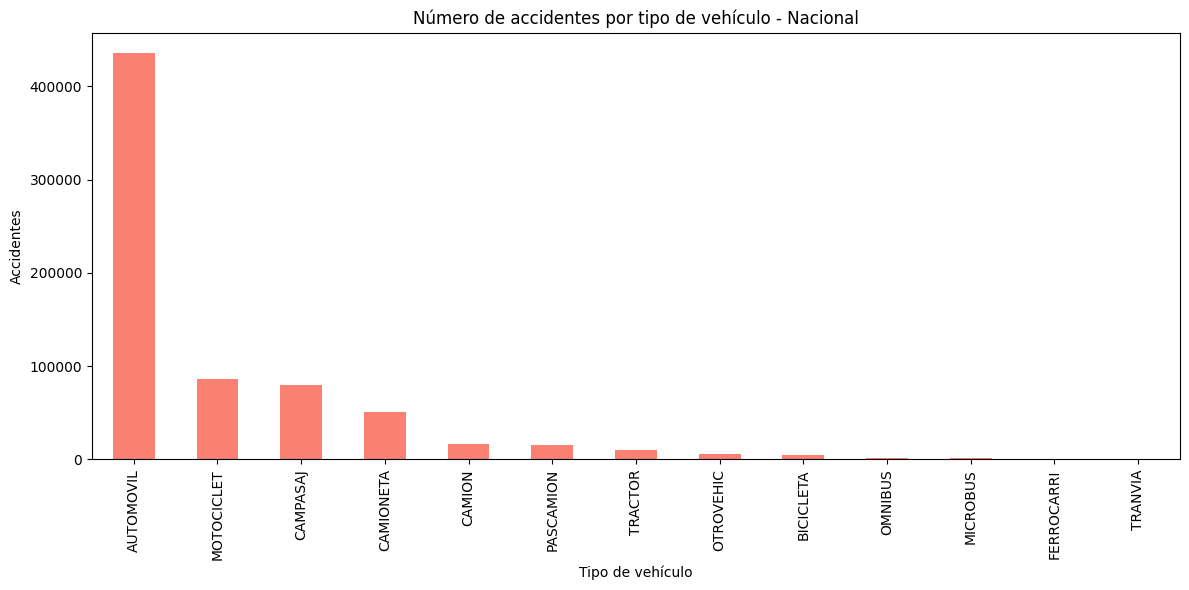

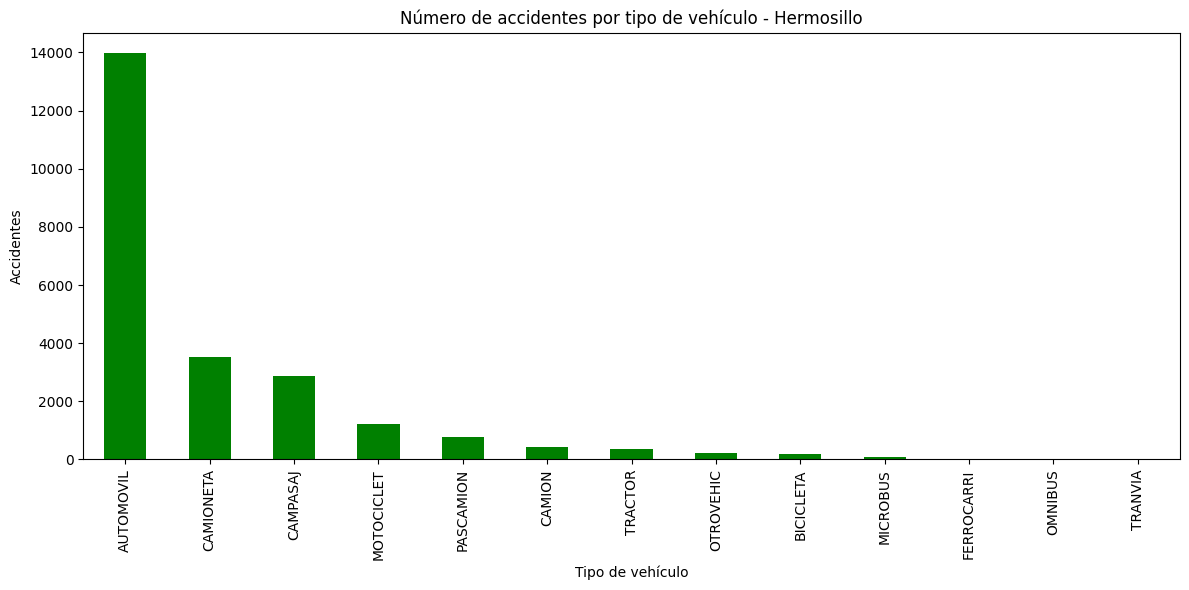

In [205]:
import matplotlib.pyplot as plt
import seaborn as sns

vehiculos_cols = ['AUTOMOVIL','CAMPASAJ','PASCAMION','MICROBUS','OMNIBUS',
                  'TRANVIA','CAMIONETA','CAMION','TRACTOR','FERROCARRI','MOTOCICLET','BICICLETA','OTROVEHIC']

# Número total de vehículos involucrados por tipo

vehiculos_total_nac = df[vehiculos_cols].sum().sort_values(ascending=False)
vehiculos_total_hermosillo = dh_hermosillo[vehiculos_cols].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
vehiculos_total_nac.plot(kind='bar', color='salmon')
plt.title('Número de accidentes por tipo de vehículo - Nacional')
plt.xlabel('Tipo de vehículo')
plt.ylabel('Accidentes')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
vehiculos_total_hermosillo.plot(kind='bar', color='green')
plt.title('Número de accidentes por tipo de vehículo - Hermosillo')
plt.xlabel('Tipo de vehículo')
plt.ylabel('Accidentes')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Tipos de vehículos más involucrados en accidentes

In [206]:
# Columnas de vehículos y víctimas
vehiculos_cols = ['AUTOMOVIL','CAMPASAJ','PASCAMION','MICROBUS','OMNIBUS',
                  'TRANVIA','CAMIONETA','CAMION','TRACTOR','FERROCARRI','MOTOCICLET','BICICLETA','OTROVEHIC']

heridos_cols = ['CONDHERIDO', 'PASAHERIDO', 'PEATHERIDO', 'CICLHERIDO', 'OTROHERIDO', 'NEHERIDO']

fallecidos_cols = ['CONDMUERTO', 'CONDHERIDO', 'PASAMUERTO', 'PASAHERIDO',
                 'PEATMUERTO','PEATHERIDO','CICLMUERTO','CICLHERIDO','OTROMUERTO','OTROHERIDO', 'NEMUERTO', 'NEHERIDO']

def analyze_vehicles(df, vehiculos_cols, heridos_cols, fallecidos_cols):
    accidentes_por_vehiculo = {}
    heridos_por_vehiculo = {}
    fallecidos_por_vehiculo = {}

    for vehiculo in vehiculos_cols:
        df_vehiculo = df[df[vehiculo] > 0]
        accidentes_por_vehiculo[vehiculo] = df_vehiculo.shape[0]
        heridos_por_vehiculo[vehiculo] = df_vehiculo[heridos_cols].sum().sum()
        fallecidos_por_vehiculo[vehiculo] = df_vehiculo[fallecidos_cols].sum().sum()

    accidentes_por_vehiculo_series = pd.Series(accidentes_por_vehiculo).sort_values(ascending=False)
    heridos_por_vehiculo_series = pd.Series(heridos_por_vehiculo).sort_values(ascending=False)
    fallecidos_por_vehiculo_series = pd.Series(fallecidos_por_vehiculo).sort_values(ascending=False)

    return accidentes_por_vehiculo_series, heridos_por_vehiculo_series, fallecidos_por_vehiculo_series

# Analyze Hermosillo data
accidentes_por_vehiculo_hmo_series, heridos_por_vehiculo_hmo_series, fallecidos_por_vehiculo_hmo_series = analyze_vehicles(dh_hermosillo, vehiculos_cols, heridos_cols, fallecidos_cols)

# Analyze National data
accidentes_por_vehiculo_nac_series, heridos_por_vehiculo_nac_series, fallecidos_por_vehiculo_nac_series = analyze_vehicles(df, vehiculos_cols, heridos_cols, fallecidos_cols)

In [207]:
# Crear DataFrames para Hermosillo y Nacional
resumen_hermosillo = pd.DataFrame({
    'Accidentes_Hermosillo': accidentes_por_vehiculo_hmo_series,
    'Heridos_Hermosillo': heridos_por_vehiculo_hmo_series,
    'Victimas_Hermosillo': fallecidos_por_vehiculo_hmo_series
})

resumen_nacional = pd.DataFrame({
    'Accidentes_Nacional': accidentes_por_vehiculo_nac_series,
    'Heridos_Nacional': heridos_por_vehiculo_nac_series,
    'Victimas_Nacional': fallecidos_por_vehiculo_nac_series
})

# Combinar los DataFrames
resumen_combinado = pd.merge(resumen_hermosillo, resumen_nacional, left_index=True, right_index=True, how='outer')

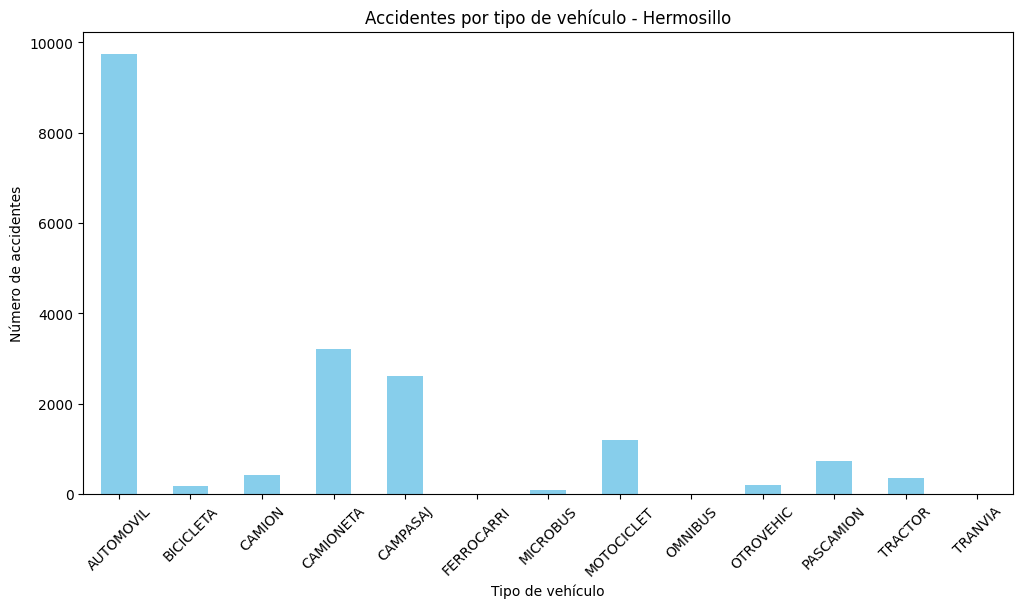

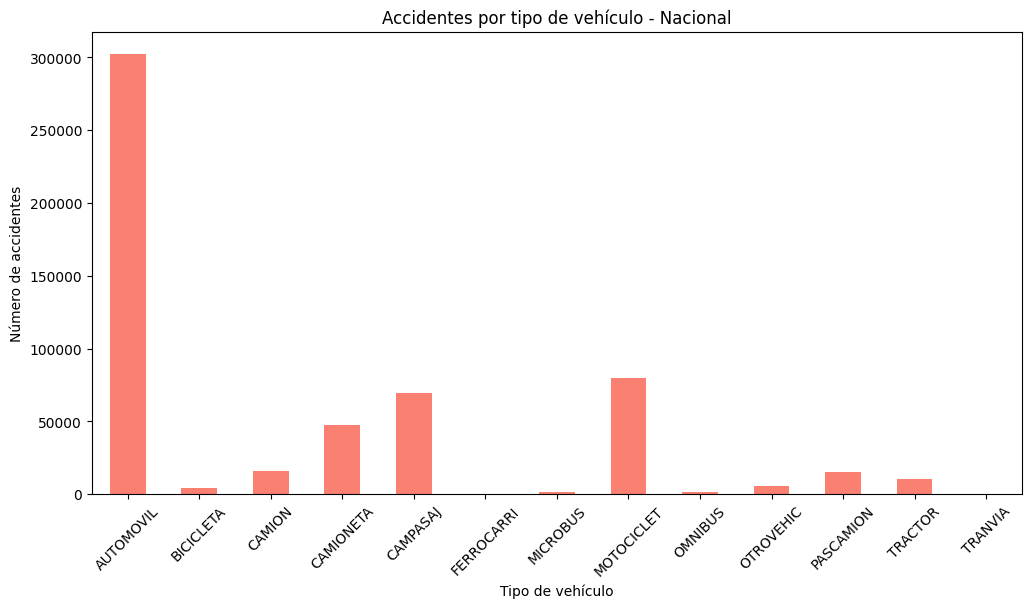

In [208]:
import matplotlib.pyplot as plt

figsize = (12,6)

# Gráfico solo Hermosillo
resumen_hermosillo['Accidentes_Hermosillo'].plot(
    kind='bar', figsize=figsize, color='skyblue', title='Accidentes por tipo de vehículo - Hermosillo'
)
plt.ylabel('Número de accidentes')
plt.xlabel('Tipo de vehículo')
plt.xticks(rotation=45)
plt.show()

# Gráfico solo Nacional
resumen_nacional['Accidentes_Nacional'].plot(
    kind='bar', figsize=figsize, color='salmon', title='Accidentes por tipo de vehículo - Nacional'
)
plt.ylabel('Número de accidentes')
plt.xlabel('Tipo de vehículo')
plt.xticks(rotation=45)
plt.show()


### Vehículos más causantes de fallecidos

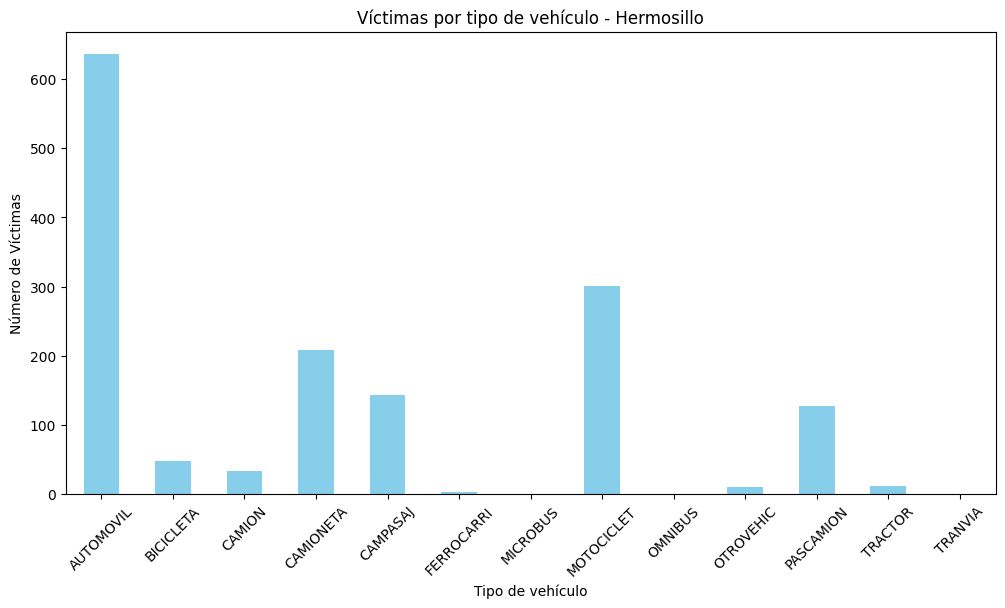

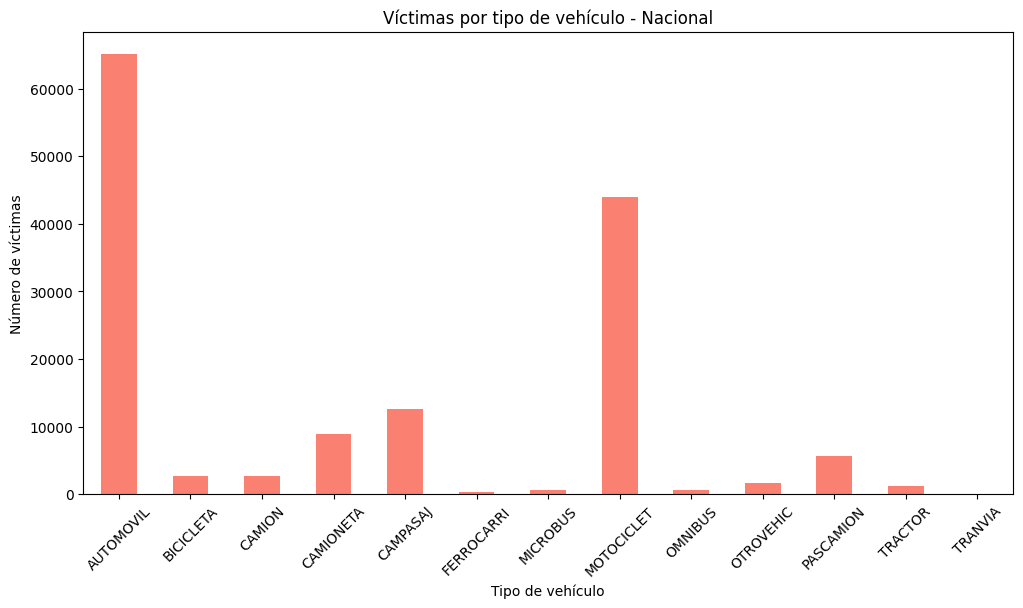

In [209]:
# Gráfico solo Hermosillo
resumen_hermosillo['Victimas_Hermosillo'].plot(
    kind='bar', figsize=figsize, color='skyblue', title='Víctimas por tipo de vehículo - Hermosillo'
)
plt.ylabel('Número de Víctimas')
plt.xlabel('Tipo de vehículo')
plt.xticks(rotation=45)
plt.show()

# Gráfico solo Nacional
resumen_nacional['Victimas_Nacional'].plot(
    kind='bar', figsize=figsize, color='salmon', title='Víctimas por tipo de vehículo - Nacional'
)
plt.ylabel('Número de víctimas')
plt.xlabel('Tipo de vehículo')
plt.xticks(rotation=45)
plt.show()

### Vehículos más causante de heridos

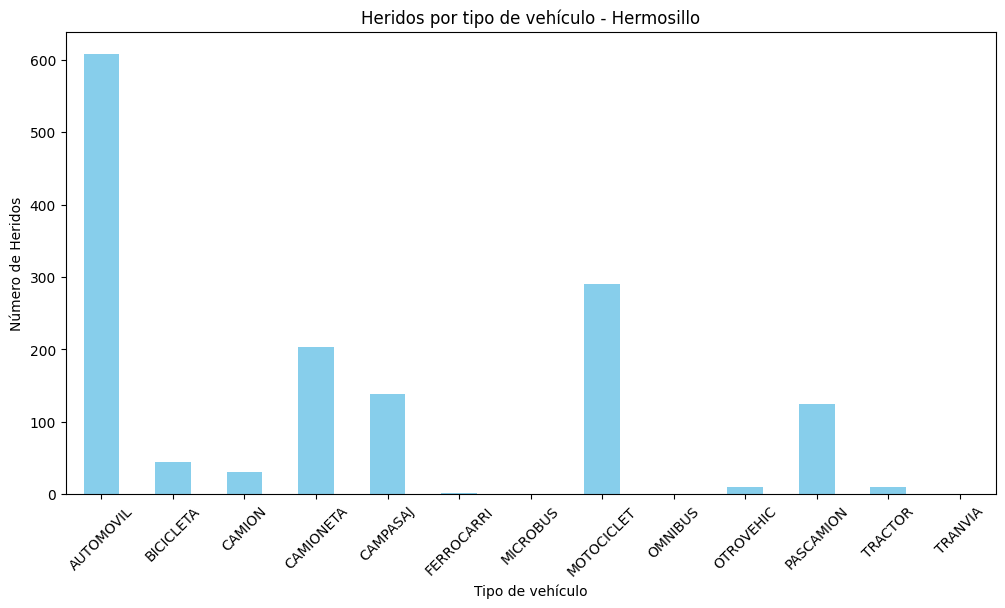

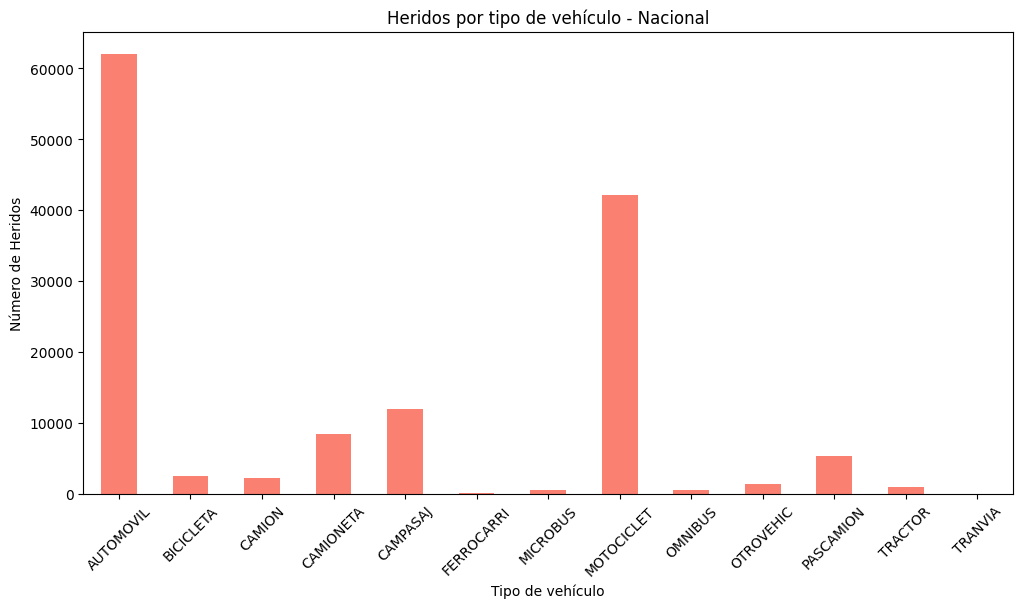

In [210]:
# Gráfico solo Hermosillo
resumen_hermosillo['Heridos_Hermosillo'].plot(
    kind='bar', figsize=figsize, color='skyblue', title='Heridos por tipo de vehículo - Hermosillo'
)
plt.ylabel('Número de Heridos')
plt.xlabel('Tipo de vehículo')
plt.xticks(rotation=45)
plt.show()

# Gráfico solo Nacional
resumen_nacional['Heridos_Nacional'].plot(
    kind='bar', figsize=figsize, color='salmon', title='Heridos por tipo de vehículo - Nacional'
)
plt.ylabel('Número de Heridos')
plt.xlabel('Tipo de vehículo')
plt.xticks(rotation=45)
plt.show()

### Relación entre tipo de accidente y el causante (heridos y fallecidos)

In [211]:
# Columnas de víctimas
victimas_cols = ['CONDMUERTO', 'CONDHERIDO', 'PASAMUERTO', 'PASAHERIDO',
                 'PEATMUERTO','PEATHERIDO','CICLMUERTO','CICLHERIDO','OTROMUERTO','OTROHERIDO', 'NEMUERTO', 'NEHERIDO']

# Nacional
victimas_por_causa_nac = df.groupby('CAUSAACCI')[victimas_cols].sum()

# Hermosillo
victimas_por_causa_herm = dh_hermosillo.groupby('CAUSAACCI')[victimas_cols].sum()

/tmp/ipython-input-1408462119.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  victimas_por_causa_nac = df.groupby('CAUSAACCI')[victimas_cols].sum()
/tmp/ipython-input-1408462119.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  victimas_por_causa_herm = dh_hermosillo.groupby('CAUSAACCI')[victimas_cols].sum()


/tmp/ipython-input-1802851236.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  victimas_total_herm = dh_hermosillo.groupby(['CAUSAACCI', 'TIPACCID'])[victimas_cols].sum().sum(axis=1).unstack(fill_value=0)
/tmp/ipython-input-1802851236.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  victimas_total_nac = df.groupby(['CAUSAACCI', 'TIPACCID'])[victimas_cols].sum().sum(axis=1).unstack(fill_value=0)


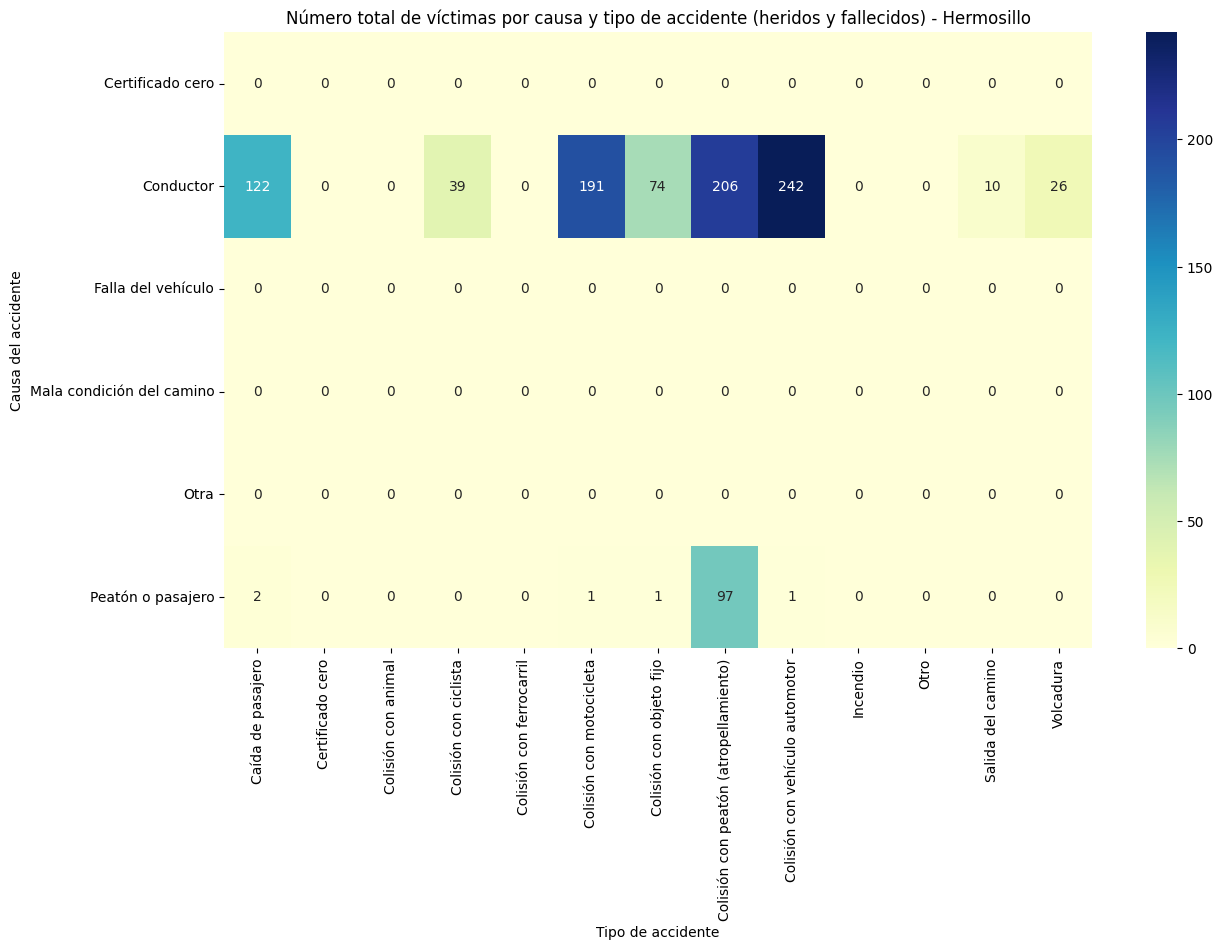

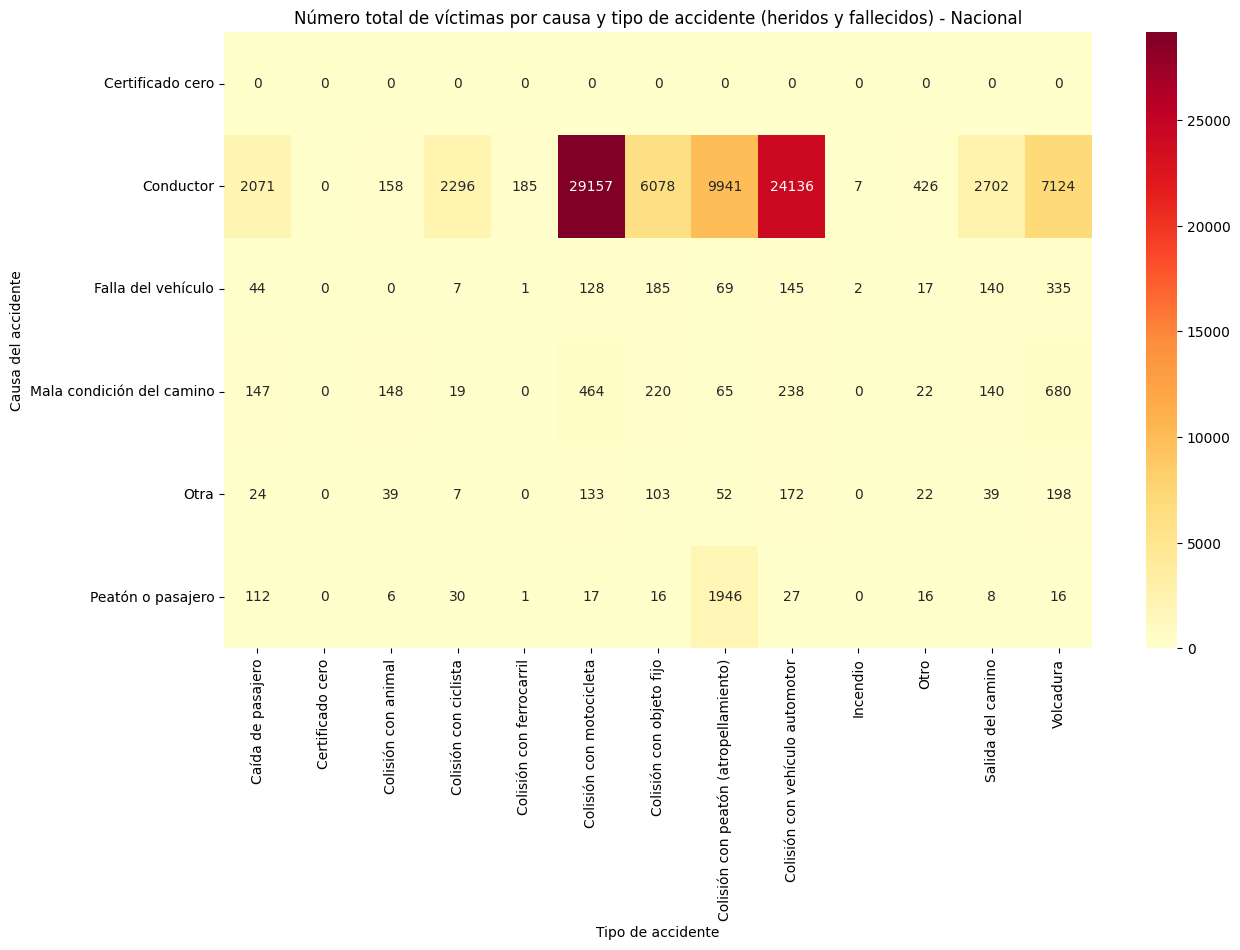

In [212]:
import matplotlib.pyplot as plt
import seaborn as sns

# Primero, sumamos las víctimas totales (muertos + heridos) por tipo de accidente y causa

# Hermosillo
victimas_total_herm = dh_hermosillo.groupby(['CAUSAACCI', 'TIPACCID'])[victimas_cols].sum().sum(axis=1).unstack(fill_value=0)

# Nacional
victimas_total_nac = df.groupby(['CAUSAACCI', 'TIPACCID'])[victimas_cols].sum().sum(axis=1).unstack(fill_value=0)

# Heatmap Hermosillo
plt.figure(figsize=(14,8))
sns.heatmap(victimas_total_herm, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Número total de víctimas por causa y tipo de accidente (heridos y fallecidos) - Hermosillo")
plt.ylabel("Causa del accidente")
plt.xlabel("Tipo de accidente")
plt.xticks(rotation=90)
plt.show()

# Heatmap Nacional
plt.figure(figsize=(14,8))
sns.heatmap(victimas_total_nac, annot=True, fmt="d", cmap="YlOrRd")
plt.title("Número total de víctimas por causa y tipo de accidente (heridos y fallecidos) - Nacional")
plt.ylabel("Causa del accidente")
plt.xlabel("Tipo de accidente")
plt.xticks(rotation=90)
plt.show()


In [213]:
victimas_por_causa = dh_hermosillo.groupby('CAUSAACCI')[victimas_cols].sum()
display(victimas_por_causa.sort_values(by='CONDMUERTO', ascending=False).head(10))

/tmp/ipython-input-4114680367.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  victimas_por_causa = dh_hermosillo.groupby('CAUSAACCI')[victimas_cols].sum()


,CONDMUERTO,CONDHERIDO,PASAMUERTO,PASAHERIDO,PEATMUERTO,PEATHERIDO,CICLMUERTO,CICLHERIDO,OTROMUERTO,OTROHERIDO,NEMUERTO,NEHERIDO
CAUSAACCI,,,,,,,,,,,,
Conductor,14,407,7,228,13,202,4,35,0,0,0,0
Certificado cero,0,0,0,0,0,0,0,0,0,0,0,0
Falla del vehículo,0,0,0,0,0,0,0,0,0,0,0,0
Mala condición del camino,0,0,0,0,0,0,0,0,0,0,0,0
Otra,0,0,0,0,0,0,0,0,0,0,0,0
Peatón o pasajero,0,2,0,2,3,95,0,0,0,0,0,0


### Muertos por accidentes en Sonora

In [214]:
# Columnas de víctimas
victimas_cols = ['CONDMUERTO', 'CONDHERIDO', 'PASAMUERTO', 'PASAHERIDO',
                 'PEATMUERTO','PEATHERIDO','CICLMUERTO','CICLHERIDO','OTROMUERTO','OTROHERIDO']

# Filtrar Sonora
dh_sonora = df[df['ID_ENTIDAD'] == 26]

# Agrupar por municipio y sumar víctimas
accidentes_graves = dh_sonora.groupby('ID_MUNICIPIO')[victimas_cols].sum()

# Columna total de muertos
accidentes_graves['TOTAL_MUERTO'] = accidentes_graves[['CONDMUERTO','PASAMUERTO','PEATMUERTO','CICLMUERTO','OTROMUERTO']].sum(axis=1)

# Reset index para mergef
accidentes_graves = accidentes_graves.reset_index()

# Merge con nombres reales de municipios
accidentes_graves = pd.merge(
    accidentes_graves,
    df_municipio[df_municipio['ID_ENTIDAD']==26][['ID_MUNICIPIO','NOM_MUNICIPIO']],
    on='ID_MUNICIPIO',
    how='left'
)

# Mostrar top 10 municipios por accidentes graves
display(accidentes_graves.sort_values('TOTAL_MUERTO', ascending=False)[['NOM_MUNICIPIO','TOTAL_MUERTO']].head(10))


/tmp/ipython-input-767430508.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  accidentes_graves = dh_sonora.groupby('ID_MUNICIPIO')[victimas_cols].sum()


,NOM_MUNICIPIO,TOTAL_MUERTO
29,Hermosillo,41
28,Guaymas,23
54,San Luis Río Colorado,21
41,Navojoa,20
17,Cajeme,15
16,Caborca,12
25,Etchojoa,11
24,Empalme,7
32,Huatabampo,6
47,Puerto Peñasco,6


### Distribución por sexo

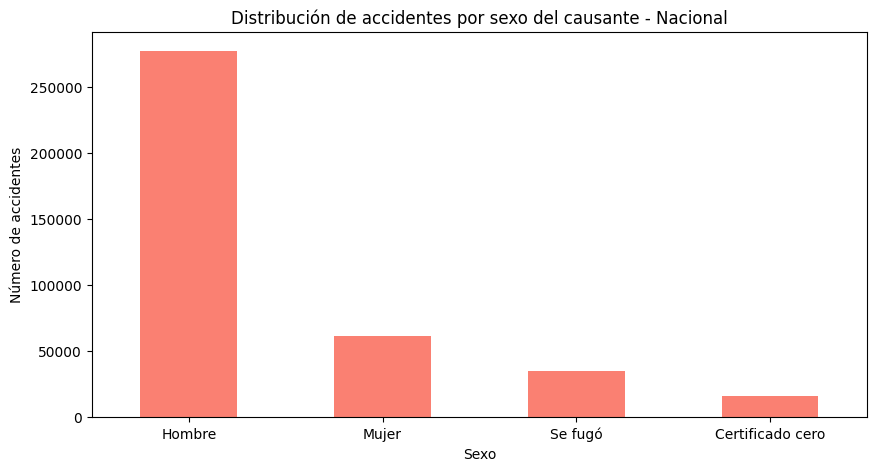

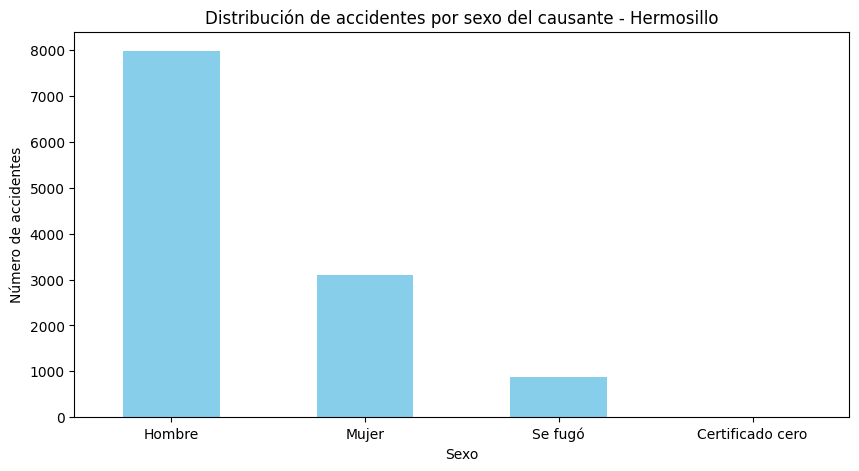

In [215]:
import matplotlib.pyplot as plt

figsize = (10,5)

# Nacional
sexo_nac = df['SEXO'].value_counts()
plt.figure(figsize=figsize)
sexo_nac.plot(kind='bar', color='salmon')
plt.title("Distribución de accidentes por sexo del causante - Nacional")
plt.ylabel("Número de accidentes")
plt.xlabel("Sexo")
plt.xticks(rotation=0)
plt.show()

# Hermosillo
sexo_herm = dh_hermosillo['SEXO'].value_counts()
plt.figure(figsize=figsize)
sexo_herm.plot(kind='bar', color='skyblue')
plt.title("Distribución de accidentes por sexo del causante - Hermosillo")
plt.ylabel("Número de accidentes")
plt.xlabel("Sexo")
plt.xticks(rotation=0)
plt.show()


## 7) Conclusiones parciales
- Principales hallazgos en calidad, análisis descriptivo y preprocesamiento.
- Estado de preparación del dataset para fases posteriores.

**Métricas de Calidad de los Datos y Limpieza:**

El dataset de ATUS 2024 no presenta valores faltantes en ninguna columna, lo cual es ideal para el análisis.

Se identificaron y eliminaron 871 filas duplicadas, lo que asegura que cada registro represente un accidente único reportado.

Se ajustaron los tipos de datos de varias columnas relevantes a tipo categórico, lo que optimiza el uso de memoria y facilita futuras operaciones de análisis y visualización.


**Análisis Descriptivo:**

- Cantidad y distribución de accidentes: Hermosillo se encuentra entre los municipios con mayor número de accidentes a nivel nacional, superando significativamente el promedio nacional por municipio. Los meses con más accidentes a nivel nacional y en Hermosillo son mayo y noviembre/diciembre, respectivamente. Las horas pico de accidentes se concentran en la tarde, especialmente alrededor de las 2 PM y 7 PM a nivel nacional, con patrones similares en Hermosillo pero con un pico más pronunciado alrededor de las 2 PM. Los viernes y sábados tienden a tener más accidentes a nivel nacional, mientras que en Hermosillo los viernes son el día con más accidentes.

- Tipos de accidentes y víctimas: La "Colisión con vehículo automotor" es el tipo de accidente más frecuente tanto a nivel nacional como en Hermosillo. En cuanto a víctimas, la "Colisión con vehículo automotor" y la "Colisión con peatón (atropellamiento)" son los tipos de accidentes que generan más heridos y fallecidos en ambos ámbitos.


- Vehículos involucrados: Los automóviles son, por mucho, los vehículos más involucrados en accidentes tanto a nivel nacional como en Hermosillo. Sin embargo, las motocicletas y los peatones son quienes presentan un mayor número de víctimas (heridos y fallecidos) en proporción a los accidentes en los que están involucrados.

- Causas y factores de riesgo: La causa principal de accidentes reportada tanto a nivel nacional como en Hermosillo es el "Conductor". El análisis de víctimas por causa y tipo de accidente (mediante los heatmaps) sugiere que la mayoría de las víctimas (heridos y fallecidos) ocurren en colisiones con vehículos automotores y atropellamientos, siendo la causa principal atribuida al conductor.

- Análisis de valores atípicos y concentraciones: Al analizar los municipios de Sonora con mayor número de fallecidos en accidentes, Hermosillo encabeza la lista, seguido por Guaymas y San Luis Río Colorado.

- Distribución por sexo: La distribución de accidentes por sexo del causante muestra que la mayoría de los accidentes son causados por hombres, tanto a nivel nacional como en Hermosillo. Faltaría comparar los datos de Hermosillo contra el padrón de automovilistas vigente en 2024 para lo cuál he solicitado a la Secretaría de Hacienda del Estado de Sonora esta información.


**Estado de preparación del dataset para fases posteriores:**

El dataset se encuentra en un buen estado de limpieza y preprocesamiento. Los valores faltantes y duplicados han sido manejados, y los tipos de datos han sido ajustados. Se ha creado un sub-DataFrame específico para Hermosillo lo que facilitará el análisis focalizado en esta ciudad. El dataset está listo para la siguiente fase de análisis que podría incluir análisis de correlaciones, identificación de patrones más complejos, o la preparación para modelos predictivos si fuera necesario en etapas posteriores del proyecto.Métricas de


# PARTE DOS Entrenamiento de modelo de IA

En esta sección estaré trabajando con el conjunto de datos con el fin de pre procesarlo antes de entrenar un modelo de inteligencia artificial.

He decidido entrenar un modelo clasificatorio de acuerdo con la gravedad del accidente. La variable elegida tiene el nombre de 'CLASACC' en el conjunto de datos. Esta cuenta con tres valores posibles: Solo daños, No fatal y Fatal

## Distribución de la variable a predecir

In [216]:
print("Recuento de valores únicos para 'CLASACC' en dh_hermosillo:")
print(dh_hermosillo['CLASACC'].value_counts())

Recuento de valores únicos para 'CLASACC' en dh_hermosillo:
CLASACC
Sólo daños    11108
No fatal        838
Fatal            39
Name: count, dtype: int64


In [217]:
print("\nPorcentaje de la variable objetivo 'CLASACC' en dh_hermosillo:")
print(dh_hermosillo['CLASACC'].value_counts(normalize=True) * 100)


Porcentaje de la variable objetivo 'CLASACC' en dh_hermosillo:
CLASACC
Sólo daños    92.682520
No fatal       6.992073
Fatal          0.325407
Name: proportion, dtype: float64


Codifico los tres posibles valores de CLASACC

In [218]:
dh_hermosillo['target_encoded'] = dh_hermosillo['CLASACC'].copy()

# Definir el mapeo de codificación
clasacc_mapping = {
    'Sólo daños': 0,
    'No fatal': 1,
    'Fatal': 2
}

# Aplicar el mapeo a la columna target_encoded
dh_hermosillo['target_encoded'] = dh_hermosillo['target_encoded'].map(clasacc_mapping)

print("Valores únicos de 'CLASACC' y 'target_encoded' después de la codificación:")
display(dh_hermosillo[['CLASACC', 'target_encoded']].head(5))

Valores únicos de 'CLASACC' y 'target_encoded' después de la codificación:


,CLASACC,target_encoded
330299,Sólo daños,0
330300,Sólo daños,0
330301,Sólo daños,0
330302,Sólo daños,0
330303,Sólo daños,0


## Eliminación de variables

Dado que el número de muertos y heridos en un accidente es una consecuencia de la clasificación del accidente, he decidido no tomarlas en cuenta para el análisis y descartarlas como posibles variables predictoras

In [219]:
predictor_variables_hermosillo = [col for col in dh_hermosillo.columns if col not in ['CLASACC', 'target_encoded']]

numerical_predictors_hermosillo = []
categorical_predictors_hermosillo = []

# Excluir explícitamente las columnas de víctimas de los predictores numéricos
excluded_victim_cols = [
    'CONDMUERTO', 'CONDHERIDO', 'PASAMUERTO', 'PASAHERIDO',
    'PEATMUERTO', 'PEATHERIDO', 'CICLMUERTO', 'CICLHERIDO'
]

for col in predictor_variables_hermosillo:
    if pd.api.types.is_numeric_dtype(dh_hermosillo[col]) and col not in excluded_victim_cols:
        numerical_predictors_hermosillo.append(col)
    elif not pd.api.types.is_numeric_dtype(dh_hermosillo[col]): # Only add non-numeric columns to categorical
        categorical_predictors_hermosillo.append(col)

print("Numerical Predictors in Hermosillo (adjusted):", numerical_predictors_hermosillo)
print("Categorical Predictors in Hermosillo:", categorical_predictors_hermosillo)

Numerical Predictors in Hermosillo (adjusted): ['ANIO', 'AUTOMOVIL', 'CAMPASAJ', 'MICROBUS', 'PASCAMION', 'OMNIBUS', 'TRANVIA', 'CAMIONETA', 'CAMION', 'TRACTOR', 'FERROCARRI', 'MOTOCICLET', 'BICICLETA', 'OTROVEHIC', 'ID_EDAD', 'OTROMUERTO', 'OTROHERIDO', 'NEMUERTO', 'NEHERIDO']
Categorical Predictors in Hermosillo: ['COBERTURA', 'ID_ENTIDAD', 'ID_MUNICIPIO', 'MES', 'ID_HORA', 'ID_MINUTO', 'ID_DIA', 'DIASEMANA', 'URBANA', 'SUBURBANA', 'TIPACCID', 'CAUSAACCI', 'CAPAROD', 'SEXO', 'ALIENTO', 'ESTATUS']


En este paso elimino aquellas columnas que sean constantes, es decir, las que tengan un mismo valor en todos los registros.

In [220]:
# Identificar las columnas constantes que deben ser eliminadas
constant_cols_to_drop = [
    'ANIO', 'OMNIBUS', 'TRANVIA', 'OTROMUERTO', 'OTROHERIDO', 'NEMUERTO', 'NEHERIDO'
]

# Eliminar las columnas constantes de dh_hermosillo
print("Dimensiones de dh_hermosillo antes de eliminar columnas constantes:", dh_hermosillo.shape)
dh_hermosillo = dh_hermosillo.drop(columns=constant_cols_to_drop, errors='ignore')
print("Columnas constantes eliminadas:", constant_cols_to_drop)
print("Dimensiones de dh_hermosillo después de eliminar columnas constantes:", dh_hermosillo.shape)

# Actualizar la lista de predictores numéricos
# Filtrar las columnas eliminadas de la lista existente de predictores numéricos
numerical_predictors_hermosillo = [
    col for col in numerical_predictors_hermosillo if col not in constant_cols_to_drop
]

print("\nNumerical Predictors in Hermosillo (updated after removing constant columns):")
print(numerical_predictors_hermosillo)


Dimensiones de dh_hermosillo antes de eliminar columnas constantes: (11985, 45)
Columnas constantes eliminadas: ['ANIO', 'OMNIBUS', 'TRANVIA', 'OTROMUERTO', 'OTROHERIDO', 'NEMUERTO', 'NEHERIDO']
Dimensiones de dh_hermosillo después de eliminar columnas constantes: (11985, 38)

Numerical Predictors in Hermosillo (updated after removing constant columns):
['AUTOMOVIL', 'CAMPASAJ', 'MICROBUS', 'PASCAMION', 'CAMIONETA', 'CAMION', 'TRACTOR', 'FERROCARRI', 'MOTOCICLET', 'BICICLETA', 'OTROVEHIC', 'ID_EDAD']


In [221]:
print(categorical_predictors_hermosillo)

['COBERTURA', 'ID_ENTIDAD', 'ID_MUNICIPIO', 'MES', 'ID_HORA', 'ID_MINUTO', 'ID_DIA', 'DIASEMANA', 'URBANA', 'SUBURBANA', 'TIPACCID', 'CAUSAACCI', 'CAPAROD', 'SEXO', 'ALIENTO', 'ESTATUS']


## Matriz de correlación: variables numéricas.

Generamos una matriz de correlación para identificar alguna posible multicolinealidad.

Aquí se analizan las variables de tipo numéricas.

In [222]:
import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionar solo las columnas numéricas ajustadas y la variable objetivo codificada
correlation_data = dh_hermosillo[numerical_predictors_hermosillo + ['target_encoded']]

# Calcular la matriz de correlación
correlation_matrix = correlation_data.corr()

print("Matriz de Correlación:")
display(correlation_matrix)


Matriz de Correlación:


,AUTOMOVIL,CAMPASAJ,MICROBUS,PASCAMION,CAMIONETA,CAMION,TRACTOR,FERROCARRI,MOTOCICLET,BICICLETA,OTROVEHIC,ID_EDAD,target_encoded
AUTOMOVIL,1.000000,-0.375907,-0.067969,-0.217082,-0.416712,-0.154504,-0.137370,-0.014701,-0.220560,-0.069832,-0.084637,-0.034719,-0.160634
CAMPASAJ,-0.375907,1.000000,-0.021567,-0.060004,-0.127528,-0.044626,-0.059800,-0.012109,-0.093700,-0.035552,-0.040418,0.032010,-0.056560
MICROBUS,-0.067969,-0.021567,1.000000,-0.021940,-0.023639,-0.006716,-0.009699,-0.002091,-0.025411,-0.010507,0.002938,0.004923,-0.023815
PASCAMION,-0.217082,-0.060004,-0.021940,1.000000,-0.089890,-0.038240,-0.029176,0.021347,0.011696,-0.014693,-0.016158,0.003375,0.071259
CAMIONETA,-0.416712,-0.127528,-0.023639,-0.089890,1.000000,-0.053298,-0.073484,-0.013924,-0.102527,-0.036757,-0.029366,0.048628,-0.042050
CAMION,-0.154504,-0.044626,-0.006716,-0.038240,-0.053298,1.000000,-0.023599,-0.004629,-0.040547,-0.005778,-0.005805,0.029134,-0.007562
TRACTOR,-0.137370,-0.059800,-0.009699,-0.029176,-0.073484,-0.023599,1.000000,0.035053,-0.046706,-0.021203,0.038155,0.020329,-0.025845
FERROCARRI,-0.014701,-0.012109,-0.002091,0.021347,-0.013924,-0.004629,0.035053,1.000000,-0.007967,-0.002936,0.023093,0.006978,0.043097
MOTOCICLET,-0.220560,-0.093700,-0.025411,0.011696,-0.102527,-0.040547,-0.046706,-0.007967,1.000000,-0.015817,-0.031566,-0.040076,0.189597
BICICLETA,-0.069832,-0.035552,-0.010507,-0.014693,-0.036757,-0.005778,-0.021203,-0.002936,-0.015817,1.000000,-0.005934,-0.000749,0.080777


In [223]:
dh_hermosillo.head(5)

,COBERTURA,ID_ENTIDAD,ID_MUNICIPIO,MES,ID_HORA,ID_MINUTO,ID_DIA,DIASEMANA,URBANA,SUBURBANA,...,CONDHERIDO,PASAMUERTO,PASAHERIDO,PEATMUERTO,PEATHERIDO,CICLMUERTO,CICLHERIDO,CLASACC,ESTATUS,target_encoded
330299,Municipal,26,30,1,2,0,1,lunes,Accidente en intersección,Sin accidente en esta zona,...,0,0,0,0,0,0,0,Sólo daños,Cifras Corregidas,0
330300,Municipal,26,30,1,2,0,1,lunes,Accidente en intersección,Sin accidente en esta zona,...,0,0,0,0,0,0,0,Sólo daños,Cifras Corregidas,0
330301,Municipal,26,30,1,6,15,1,lunes,Accidente en intersección,Sin accidente en esta zona,...,0,0,0,0,0,0,0,Sólo daños,Cifras Corregidas,0
330302,Municipal,26,30,1,6,30,1,lunes,Accidente en intersección,Sin accidente en esta zona,...,0,0,0,0,0,0,0,Sólo daños,Cifras Corregidas,0
330303,Municipal,26,30,1,8,50,1,lunes,Accidente en intersección,Sin accidente en esta zona,...,0,0,0,0,0,0,0,Sólo daños,Cifras Corregidas,0


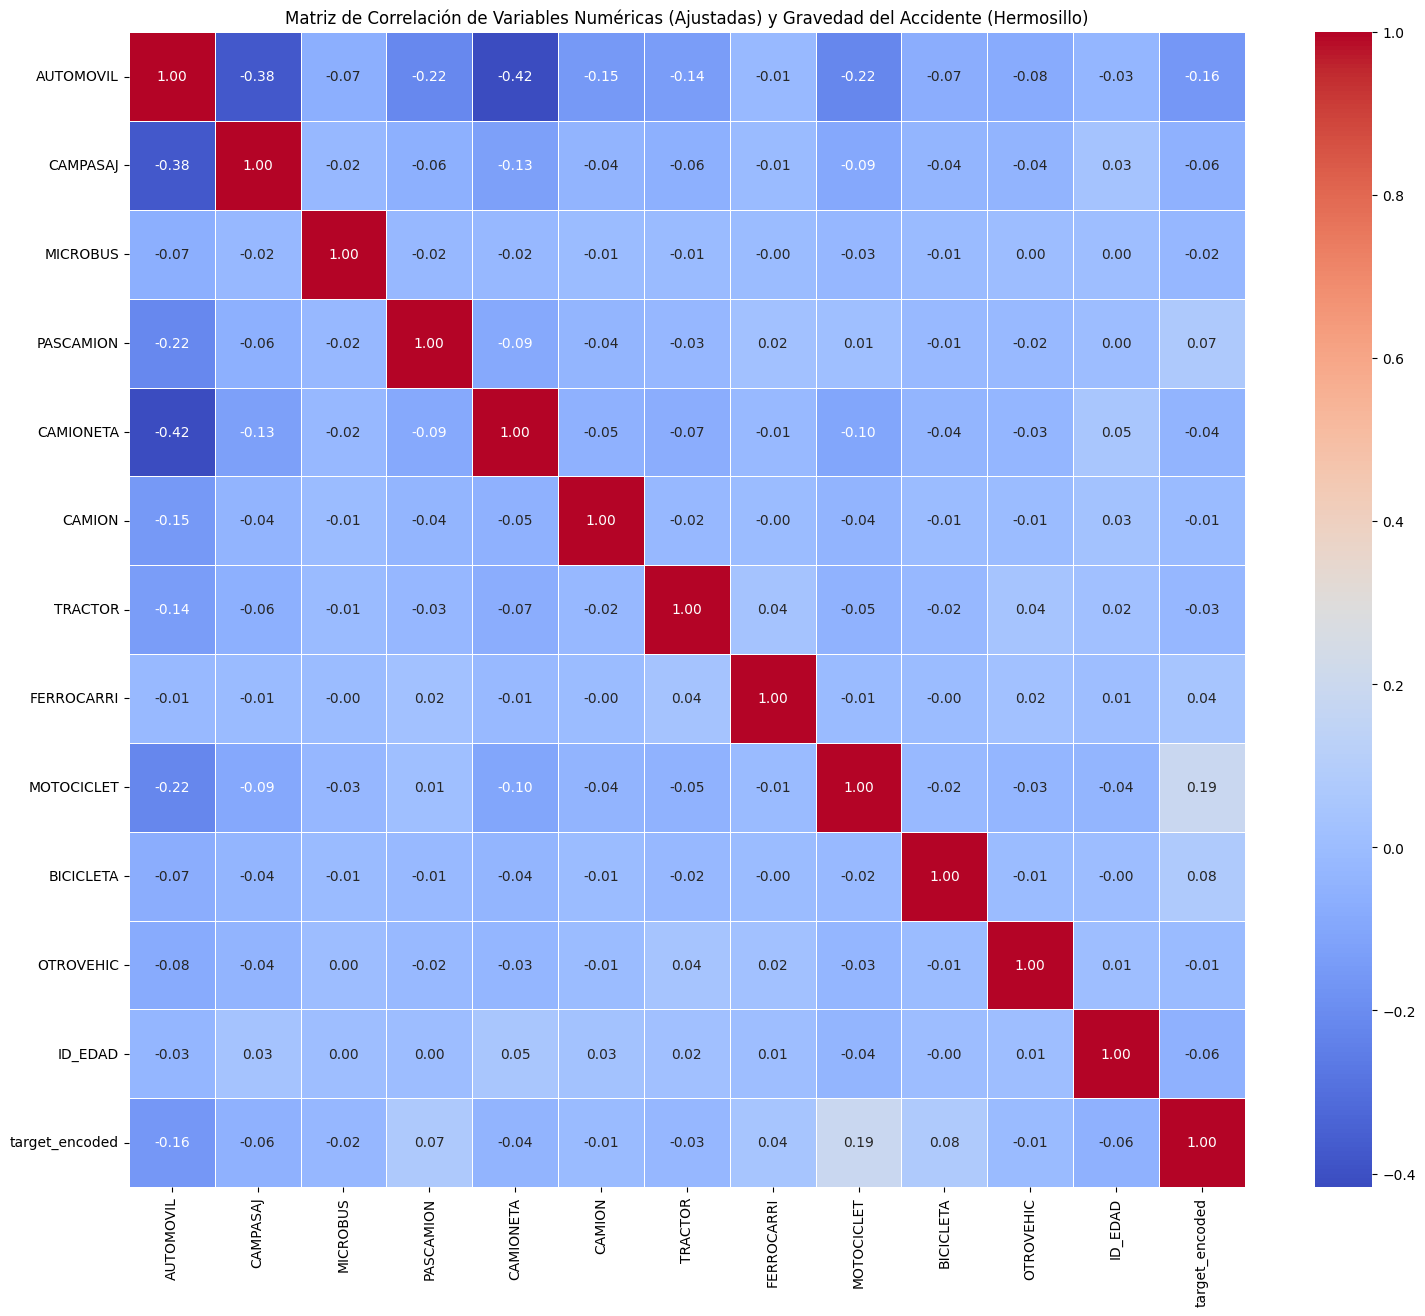

In [224]:
# Visualizar la matriz de correlación con un mapa de calor
plt.figure(figsize=(18, 15))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Matriz de Correlación de Variables Numéricas (Ajustadas) y Gravedad del Accidente (Hermosillo)')
plt.show()

Al igual que en el paso anterior, se analizan las columnas de tipo categórico para identificar una posible multicolinealidad entre ellas. Asimismo, se eliminar aquellas columnas que sean constantes y con ello no representen algún valor importante para el modelo.

In [225]:
# Identificar columnas categóricas constantes
constant_categorical_cols_to_drop = []

# Iterate over the original categorical predictors list
for col in categorical_predictors_hermosillo:
    if col in dh_hermosillo.columns: # Ensure the column still exists
        if dh_hermosillo[col].nunique() == 1:
            constant_categorical_cols_to_drop.append(col)

# Eliminar las columnas categóricas constantes de dh_hermosillo
print("Dimensiones de dh_hermosillo antes de eliminar columnas categóricas constantes:", dh_hermosillo.shape)
if constant_categorical_cols_to_drop:
    dh_hermosillo = dh_hermosillo.drop(columns=constant_categorical_cols_to_drop, errors='ignore')
    print("Columnas categóricas constantes eliminadas:", constant_categorical_cols_to_drop)
else:
    print("No se encontraron columnas categóricas constantes adicionales para eliminar.")
print("Dimensiones de dh_hermosillo después de eliminar columnas categóricas constantes:", dh_hermosillo.shape)

# Actualizar la lista de predictores categóricos
categorical_predictors_hermosillo = [
    col for col in categorical_predictors_hermosillo if col not in constant_categorical_cols_to_drop
]

print("\nCategorical Predictors in Hermosillo (updated after removing constant columns):")
print(categorical_predictors_hermosillo)


Dimensiones de dh_hermosillo antes de eliminar columnas categóricas constantes: (11985, 38)
Columnas categóricas constantes eliminadas: ['COBERTURA', 'ID_ENTIDAD', 'ID_MUNICIPIO', 'ESTATUS']
Dimensiones de dh_hermosillo después de eliminar columnas categóricas constantes: (11985, 34)

Categorical Predictors in Hermosillo (updated after removing constant columns):
['MES', 'ID_HORA', 'ID_MINUTO', 'ID_DIA', 'DIASEMANA', 'URBANA', 'SUBURBANA', 'TIPACCID', 'CAUSAACCI', 'CAPAROD', 'SEXO', 'ALIENTO']


Para identificar aquellas variables categóricas con una mayor correlación con la variable objetivos se utiliza el método V de Cramer. En este análisis vemos que lás variables más fuertes serían TIPACCID, CAUSAACCI y ALIENTO.

De igual manera, se ilustra en el mapa de calor la correlación entre las variables predictoras para así identificar una posible multicolinealidad.


V de Cramer entre variables categóricas predictoras y la gravedad del accidente:


,Categorical Variable,Cramers_V_with_Target
0,TIPACCID,0.497743
1,CAUSAACCI,0.223821
2,ALIENTO,0.123641
3,SEXO,0.099057
4,ID_HORA,0.087162
5,ID_MINUTO,0.081199
6,URBANA,0.074220
7,SUBURBANA,0.072316
8,MES,0.065337
9,DIASEMANA,0.057168



Matriz de V de Cramer entre variables categóricas predictoras:


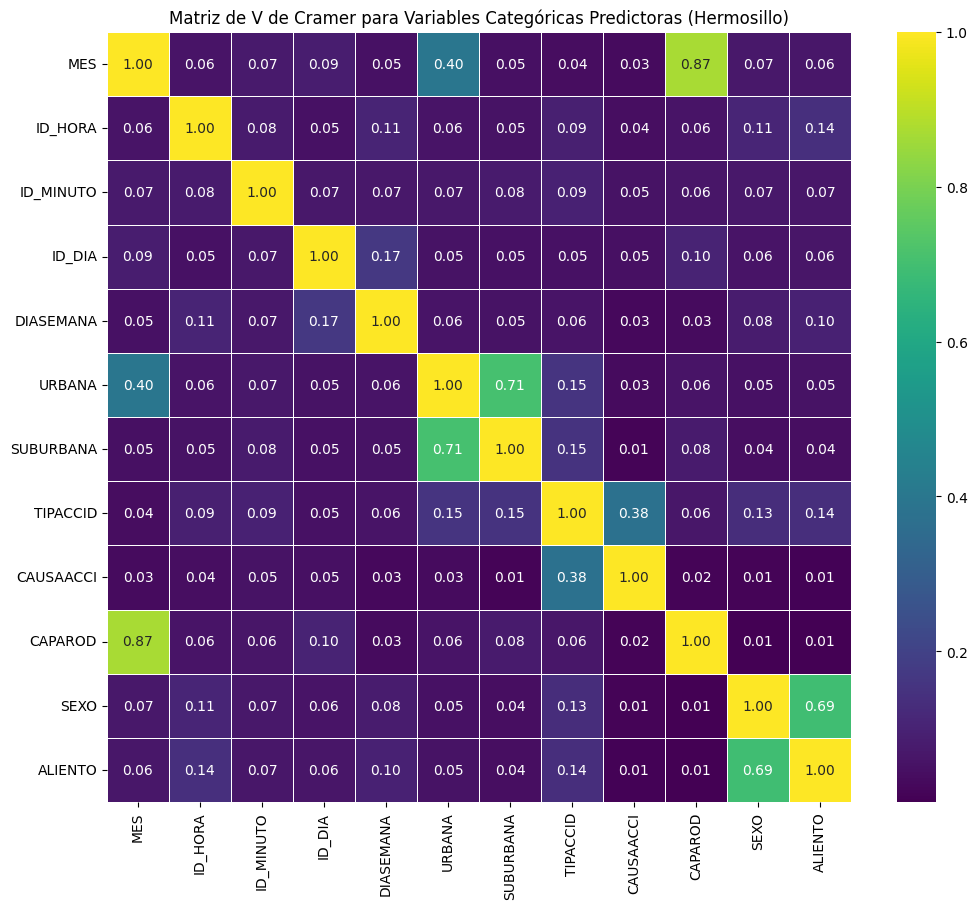

In [226]:
from scipy.stats import chi2_contingency
import numpy as np
import pandas as pd

def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape
    phi2 = chi2 / n
    v = np.sqrt(phi2 / min(k - 1, r - 1))
    return v

# Crear una copia de target_encoded y convertirla a tipo category
# Esto es importante porque cramers_v está diseñada para variables categóricas
dh_hermosillo['target_encoded_cat'] = dh_hermosillo['target_encoded'].astype('category')

# 1. V de Cramer entre variables categóricas predictoras y target_encoded
cramers_v_target = {}
for col in categorical_predictors_hermosillo:
    # Asegurarse de que la columna sea de tipo category o object antes de calcular
    if dh_hermosillo[col].dtype.name != 'category' and dh_hermosillo[col].dtype.name != 'object':
        dh_hermosillo[col] = dh_hermosillo[col].astype('category')
    cramers_v_target[col] = cramers_v(dh_hermosillo[col], dh_hermosillo['target_encoded_cat'])

cramers_v_target_df = pd.DataFrame(cramers_v_target.items(), columns=['Categorical Variable', 'Cramers_V_with_Target'])
cramers_v_target_df = cramers_v_target_df.sort_values(by='Cramers_V_with_Target', ascending=False).reset_index(drop=True)

print("\nV de Cramer entre variables categóricas predictoras y la gravedad del accidente:")
display(cramers_v_target_df)

# 2. V de Cramer entre todas las parejas de variables categóricas predictoras
num_categorical_cols = len(categorical_predictors_hermosillo)
cramers_v_matrix = pd.DataFrame(index=categorical_predictors_hermosillo, columns=categorical_predictors_hermosillo)

for i in range(num_categorical_cols):
    for j in range(i, num_categorical_cols):
        col1 = categorical_predictors_hermosillo[i]
        col2 = categorical_predictors_hermosillo[j]
        # Asegurarse de que las columnas sean de tipo category o object antes de calcular
        if dh_hermosillo[col1].dtype.name != 'category' and dh_hermosillo[col1].dtype.name != 'object':
            dh_hermosillo[col1] = dh_hermosillo[col1].astype('category')
        if dh_hermosillo[col2].dtype.name != 'category' and dh_hermosillo[col2].dtype.name != 'object':
            dh_hermosillo[col2] = dh_hermosillo[col2].astype('category')

        if col1 == col2:
            cramers_v_matrix.loc[col1, col2] = 1.0
        else:
            v_val = cramers_v(dh_hermosillo[col1], dh_hermosillo[col2])
            cramers_v_matrix.loc[col1, col2] = v_val
            cramers_v_matrix.loc[col2, col1] = v_val

print("\nMatriz de V de Cramer entre variables categóricas predictoras:")
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12, 10))
sns.heatmap(cramers_v_matrix.astype(float), annot=True, cmap='viridis', fmt=".2f", linewidths=.5)
plt.title('Matriz de V de Cramer para Variables Categóricas Predictoras (Hermosillo)')
plt.show()

Después del análisis de las variables categóricas, he decidido eliminar CAPAROD por su alta correlación con MES y su baja correlación con la variable objetivo; eliminarpe SUBURBANA por su alta correlación con URBANA y ALIENTO ya que tan solo 87 registros de los ~11 000 registros de accidentes en Hermosillo tienen el valor de Sí.

También decidí eliminar la variable de recuento de heridos y muertos que que estos representan una consecuencia del tipo de accidente y no una probable causa.

In [227]:
# Eliminar las columnas 'CAPAROD', 'SUBURBANA' y 'ALIENTO' de dh_hermosillo
print("Dimensiones de dh_hermosillo antes de eliminar columnas adicionales:", dh_hermosillo.shape)
dh_hermosillo = dh_hermosillo.drop(columns=['CAPAROD', 'SUBURBANA', 'ALIENTO'])
print("Dimensiones de dh_hermosillo después de eliminar columnas adicionales:", dh_hermosillo.shape)


Dimensiones de dh_hermosillo antes de eliminar columnas adicionales: (11985, 35)
Dimensiones de dh_hermosillo después de eliminar columnas adicionales: (11985, 32)


In [228]:
# También vamos a actualizar nuestras listas de predictores tras esta eliminación

# Excluir explícitamente las columnas de víctimas y las eliminadas de los predictores numéricos
excluded_cols_for_predictors = [
    'CLASACC', 'target_encoded', 'target_encoded_cat',
    'CONDMUERTO', 'CONDHERIDO', 'PASAMUERTO', 'PASAHERIDO',
    'PEATMUERTO', 'PEATHERIDO', 'CICLMUERTO', 'CICLHERIDO',
    'CAPAROD','CAPAROD', 'SUBURBANA', 'ALIENTO'
]

predictor_variables_hermosillo = [col for col in dh_hermosillo.columns if col not in excluded_cols_for_predictors]

numerical_predictors_hermosillo = []
categorical_predictors_hermosillo = []

for col in predictor_variables_hermosillo:
    if pd.api.types.is_numeric_dtype(dh_hermosillo[col]):
        numerical_predictors_hermosillo.append(col)
    elif not pd.api.types.is_numeric_dtype(dh_hermosillo[col]):
        categorical_predictors_hermosillo.append(col)

print("\nNumerical Predictors in Hermosillo (final):", numerical_predictors_hermosillo)
print("Categorical Predictors in Hermosillo (final):", categorical_predictors_hermosillo)


Numerical Predictors in Hermosillo (final): ['AUTOMOVIL', 'CAMPASAJ', 'MICROBUS', 'PASCAMION', 'CAMIONETA', 'CAMION', 'TRACTOR', 'FERROCARRI', 'MOTOCICLET', 'BICICLETA', 'OTROVEHIC', 'ID_EDAD']
Categorical Predictors in Hermosillo (final): ['MES', 'ID_HORA', 'ID_MINUTO', 'ID_DIA', 'DIASEMANA', 'URBANA', 'TIPACCID', 'CAUSAACCI', 'SEXO']


Como se puede observar en la tabla de VIF y en el gráfico de barras, todos los valores de VIF están muy por debajo del umbral común de 5 o 10. El valor más alto es para AUTOMOVIL con aproximadamente 3.34, y el resto son aún más bajos.

Esto significa que no hay evidencia de multicolinealidad severa entre las variables predictoras numéricas. Cada una de estas variables aporta información relativamente independiente, lo cual es ideal para la mayoría de los modelos de machine learning. No será necesario eliminar ninguna de estas variables por problemas de multicolinealidad.

VIF para variables predictoras numéricas (Hermosillo):


,feature,VIF
0,AUTOMOVIL,3.340396
1,CAMIONETA,2.246421
2,CAMPASAJ,2.038657
3,MOTOCICLET,1.464305
4,PASCAMION,1.365996
5,TRACTOR,1.220285
6,CAMION,1.215485
7,OTROVEHIC,1.065609
8,BICICLETA,1.061914
9,MICROBUS,1.047706


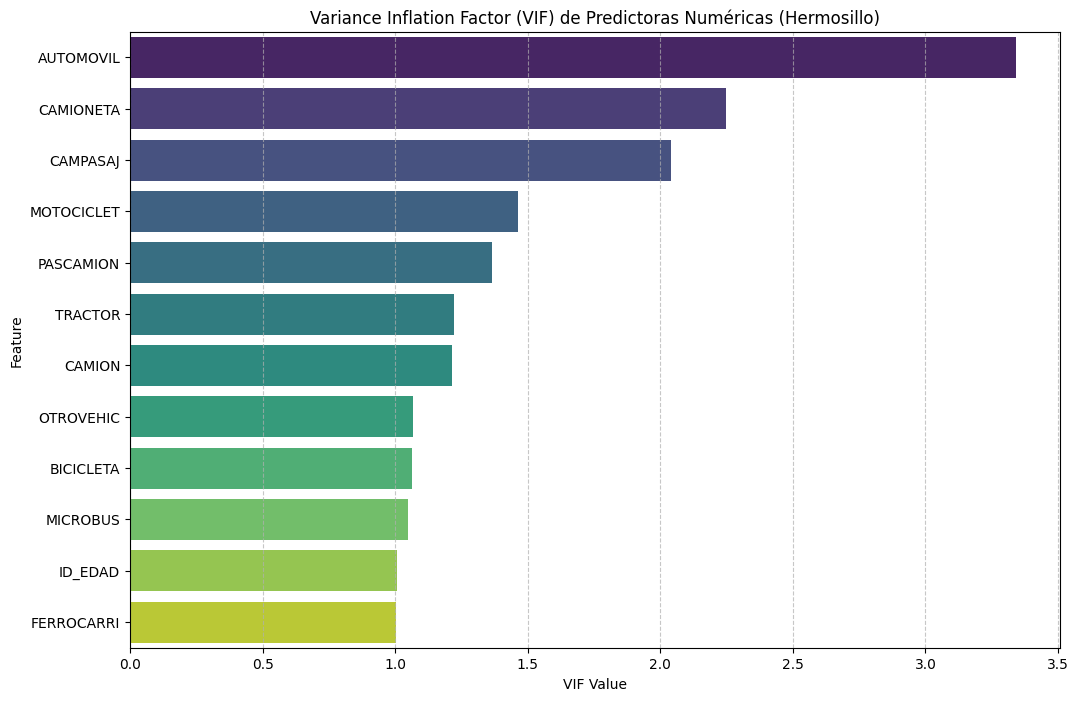

In [229]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Asegurarse de que solo estamos trabajando con las variables numéricas finales
# y excluimos 'ANIO' si se determinó que no es relevante o es constante (aunque ya lo eliminamos)

# Seleccionar solo las columnas numéricas para el cálculo del VIF
X = dh_hermosillo[numerical_predictors_hermosillo].select_dtypes(include=np.number)

# Añadir una constante al modelo para el cálculo del VIF
X['intercept'] = 1

vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

# Eliminar la fila del intercepto para la visualización, ya que no es un predictor
vif_data = vif_data[vif_data['feature'] != 'intercept']

# Ordenar por VIF de mayor a menor
vif_data = vif_data.sort_values(by="VIF", ascending=False).reset_index(drop=True)

print("VIF para variables predictoras numéricas (Hermosillo):")
display(vif_data)

# Visualizar el VIF
plt.figure(figsize=(12, 8))
sns.barplot(x='VIF', y='feature', data=vif_data, palette='viridis', hue='feature', legend=False)
plt.title('Variance Inflation Factor (VIF) de Predictoras Numéricas (Hermosillo)')
plt.xlabel('VIF Value')
plt.ylabel('Feature')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

## One-Hot encoding de las variables categóricas

In [230]:
import pandas as pd

# Realizar One-Hot Encoding en las variables categóricas
dh_hermosillo_encoded = pd.get_dummies(dh_hermosillo, columns=categorical_predictors_hermosillo, drop_first=True)

# Verificar la forma del nuevo DataFrame
print("Dimensiones del DataFrame después del One-Hot Encoding:", dh_hermosillo_encoded.shape)

# Mostrar las primeras filas del DataFrame codificado para verificar
print("\nPrimeras 5 filas del DataFrame codificado:")
display(dh_hermosillo_encoded.head())

# Opcional: Actualizar la lista de predictores numéricos para incluir las nuevas columnas dummy
# Sin embargo, para fines de modelado, trabajaremos con dh_hermosillo_encoded directamente.

Dimensiones del DataFrame después del One-Hot Encoding: (11985, 174)

Primeras 5 filas del DataFrame codificado:


,AUTOMOVIL,CAMPASAJ,MICROBUS,PASCAMION,CAMIONETA,CAMION,TRACTOR,FERROCARRI,MOTOCICLET,BICICLETA,...,TIPACCID_Salida del camino,TIPACCID_Volcadura,CAUSAACCI_Conductor,CAUSAACCI_Falla del vehículo,CAUSAACCI_Mala condición del camino,CAUSAACCI_Otra,CAUSAACCI_Peatón o pasajero,SEXO_Hombre,SEXO_Mujer,SEXO_Se fugó
330299,1,1,0,0,0,0,0,0,0,0,...,False,False,True,False,False,False,False,False,True,False
330300,1,0,0,0,0,0,0,0,0,0,...,False,False,True,False,False,False,False,True,False,False
330301,1,0,0,0,0,0,0,0,0,0,...,False,False,True,False,False,False,False,False,False,True
330302,1,0,0,0,1,0,0,0,0,0,...,False,False,True,False,False,False,False,False,False,True
330303,1,0,0,0,1,0,0,0,0,0,...,False,False,True,False,False,False,False,True,False,False


## Eliminar las columnas constantes _Certificado cero

In [231]:
# Identificar y eliminar las columnas constantes '_Certificado cero'
certificado_cero_cols = [col for col in dh_hermosillo_encoded.columns if col.endswith('_Certificado cero')]

print("Dimensiones del DataFrame antes de eliminar columnas '_Certificado cero':", dh_hermosillo_encoded.shape)
dh_hermosillo_encoded = dh_hermosillo_encoded.drop(columns=certificado_cero_cols)
print("Columnas '_Certificado cero' eliminadas:", certificado_cero_cols)
print("Dimensiones del DataFrame después de eliminar columnas '_Certificado cero':", dh_hermosillo_encoded.shape)

Dimensiones del DataFrame antes de eliminar columnas '_Certificado cero': (11985, 174)
Columnas '_Certificado cero' eliminadas: ['TIPACCID_Certificado cero']
Dimensiones del DataFrame después de eliminar columnas '_Certificado cero': (11985, 173)


In [232]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, recall_score, precision_score, f1_score
import numpy as np

# Columnas a eliminar para evitar fuga de datos
leakage_cols = [
    'CONDMUERTO', 'CONDHERIDO', 'PASAMUERTO', 'PASAHERIDO',
    'PEATMUERTO', 'PEATHERIDO', 'CICLMUERTO', 'CICLHERIDO'
]

# Preparar X (features) y y (target)
# La variable target_encoded ya está en dh_hermosillo_encoded
X = dh_hermosillo_encoded.drop(columns=['CLASACC', 'target_encoded', 'target_encoded_cat'] + leakage_cols)
y = dh_hermosillo_encoded['target_encoded']

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (11985, 162)
Dimensiones de y: (11985,)


## División del dataset en train y test

In [233]:
# Dividir los datos en conjuntos de entrenamiento y prueba (80% entrenamiento, 20% prueba)
# Usamos stratify=y para asegurar que la proporción de clases se mantenga en ambos conjuntos,
# lo cual es crucial para clases desbalanceadas.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Forma de X_train:", X_train.shape)
print("Forma de X_test:", X_test.shape)
print("Forma de y_train:", y_train.shape)
print("Forma de y_test:", y_test.shape)

# Verificar la distribución de clases en y_train y y_test
print("\nDistribución de clases en y_train:")
print(y_train.value_counts(normalize=True))
print("\nDistribución de clases en y_test:")
print(y_test.value_counts(normalize=True))

Forma de X_train: (9588, 162)
Forma de X_test: (2397, 162)
Forma de y_train: (9588,)
Forma de y_test: (2397,)

Distribución de clases en y_train:
target_encoded
0    0.926783
1    0.069983
2    0.003233
Name: proportion, dtype: float64

Distribución de clases en y_test:
target_encoded
0    0.926992
1    0.069670
2    0.003338
Name: proportion, dtype: float64


## Escalado de variables numéricas

In [234]:
# Escalar las variables numéricas (StandardScaler)
# Aunque XGBoost no requiere escalado, es una buena práctica general y puede ayudar
# si luego exploramos otros modelos sensibles a la escala.
# Identificamos columnas numéricas que no son dummies (las que no tienen prefijo de categoría)
numerical_cols_to_scale = [col for col in numerical_predictors_hermosillo if col in X_train.columns]

scaler = StandardScaler()
X_train[numerical_cols_to_scale] = scaler.fit_transform(X_train[numerical_cols_to_scale])
X_test[numerical_cols_to_scale] = scaler.transform(X_test[numerical_cols_to_scale])

print("Primeras 5 filas de X_train (escalado):")
display(X_train.head())

Primeras 5 filas de X_train (escalado):


,AUTOMOVIL,CAMPASAJ,MICROBUS,PASCAMION,CAMIONETA,CAMION,TRACTOR,FERROCARRI,MOTOCICLET,BICICLETA,...,TIPACCID_Salida del camino,TIPACCID_Volcadura,CAUSAACCI_Conductor,CAUSAACCI_Falla del vehículo,CAUSAACCI_Mala condición del camino,CAUSAACCI_Otra,CAUSAACCI_Peatón o pasajero,SEXO_Hombre,SEXO_Mujer,SEXO_Se fugó
334814,-0.222956,1.582565,-0.088822,-0.258038,-0.576204,-0.189551,-0.174817,-0.02703,-0.326749,-0.118715,...,False,False,True,False,False,False,False,True,False,False
334983,1.118979,1.582565,-0.088822,-0.258038,-0.576204,-0.189551,-0.174817,-0.02703,-0.326749,-0.118715,...,False,False,True,False,False,False,False,True,False,False
335778,-0.222956,-0.500867,-0.088822,-0.258038,-0.576204,5.063092,-0.174817,-0.02703,-0.326749,-0.118715,...,False,False,True,False,False,False,False,True,False,False
330989,-0.222956,-0.500867,-0.088822,-0.258038,-0.576204,-0.189551,-0.174817,-0.02703,2.957183,-0.118715,...,False,False,True,False,False,False,False,True,False,False
331495,1.118979,-0.500867,-0.088822,-0.258038,-0.576204,-0.189551,-0.174817,-0.02703,-0.326749,-0.118715,...,False,False,True,False,False,False,False,False,True,False


## Manejo de clases no balanceadas

Como era de esperarse, la clase minoritaria son los accientes fatales. En lugar de probar oversampling (por que undersampling sería sumamente drástico), preferí darle un peso mucho mayor a la clase Fatal y un peso menor a la clase mayoritaria.

In [255]:
# Calcular pesos de clase para manejar el desbalance
# Usaremos la inversa de la frecuencia de cada clase
class_counts = y_train.value_counts()
total_samples = len(y_train)
class_weights = {
    0: total_samples / (class_counts[0] * 30), # Peso menor para la clase mayoritaria
    1: total_samples / (class_counts[1] * 10),
    2: total_samples / class_counts[2] # Peso mayor para la clase minoritaria
}

# Ajuste manual para la clase 0 ('Sólo daños') para que el peso no sea excesivo,
# ya que es la clase más abundante y queremos evitar que el modelo se sature con ella.
# Los pesos se pueden ajustar de forma experimental.
# Aquí, por ejemplo, damos un tercio del peso 'inverso' a la clase 0.

# Los pesos para XGBoost se suelen pasar como un array para cada muestra, no por clase directamente
# Creamos un array de pesos para cada muestra en el conjunto de entrenamiento
sample_weights = np.array([class_weights[label] for label in y_train])

print("Pesos de clase calculados:", class_weights)
print("Primeros 10 pesos de muestra (ejemplo):")
print(sample_weights[:10])

Pesos de clase calculados: {0: np.float64(0.03596668917398154), 1: np.float64(1.4289120715350223), 2: np.float64(309.2903225806452)}
Primeros 10 pesos de muestra (ejemplo):
[0.03596669 0.03596669 0.03596669 0.03596669 0.03596669 0.03596669
 1.42891207 0.03596669 1.42891207 0.03596669]


Aqui intenté volver a recalcular los pesos de las clases usando sklearn para comparar con el método anteior.

In [256]:
from sklearn.utils import class_weight

# Calcular pesos de clase usando compute_class_weight con estrategia 'balanced'
# Esto asigna pesos inversamente proporcionales a la frecuencia de la clase
class_weights_array = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

# Crear un diccionario para mapear las clases a sus pesos
class_weights_balanced = dict(zip(np.unique(y_train), class_weights_array))

# Crear un array de pesos para cada muestra en el conjunto de entrenamiento
sample_weights_balanced = np.array([class_weights_balanced[label] for label in y_train])

print("Pesos de clase calculados con 'balanced' strategy:", class_weights_balanced)
print("Primeros 10 pesos de muestra (ejemplo):")
print(sample_weights_balanced[:10])

Pesos de clase calculados con 'balanced' strategy: {np.int64(0): np.float64(0.3596668917398154), np.int64(1): np.float64(4.763040238450075), np.int64(2): np.float64(103.09677419354838)}
Primeros 10 pesos de muestra (ejemplo):
[0.35966689 0.35966689 0.35966689 0.35966689 0.35966689 0.35966689
 4.76304024 0.35966689 4.76304024 0.35966689]


Modelo entrenado con método 1 de balanceo

In [262]:
import xgboost as xgb

# Entrenar el modelo XGBoost
# num_class = 3 porque tenemos 3 clases (0, 1, 2)
# objective = 'multi:softmax' para clasificación multiclase donde cada instancia pertenece a una clase mutuamente exclusiva
# eval_metric = 'mlogloss' es una métrica común para problemas de clasificación multiclase

xgb_model = xgb.XGBClassifier(
    objective='multi:softmax',
    num_class=3,
    eval_metric='mlogloss',
    n_estimators=100, # Número de árboles-
    learning_rate=0.001,
    random_state=42
)

print("Entrenando modelo XGBoost...")
xgb_model.fit(X_train, y_train, sample_weight=sample_weights_balanced)
print("Modelo entrenado.")

Entrenando modelo XGBoost...
Modelo entrenado.


Modelo con método 2 de balanceo

In [260]:
# Entrenar el modelo XGBoost
# num_class = 3 porque tenemos 3 clases (0, 1, 2)
# objective = 'multi:softmax' para clasificación multiclase donde cada instancia pertenece a una clase mutuamente exclusiva
# eval_metric = 'mlogloss' es una métrica común para problemas de clasificación multiclase

xgb_model_balanced = XGBClassifier(
    objective='multi:softmax',
    num_class=3,
    eval_metric='mlogloss',
    n_estimators=100, # Número de árboles
    learning_rate=0.001,
    random_state=42
)

print("Entrenando modelo XGBoost...")
xgb_model_balanced.fit(X_train, y_train, sample_weight=sample_weights_balanced) # Use the newly calculated sample_weights_balanced
print("Modelo entrenado.")

Entrenando modelo XGBoost...
Modelo entrenado.


In [263]:
# Realizar predicciones en el conjunto de prueba
y_pred = xgb_model.predict(X_test)

# Evaluar el modelo
print("\n--- Métricas de Evaluación del Modelo XGBoost ---")
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred))

print("\nMatriz de Confusión:")
print(confusion_matrix(y_test, y_pred))

# Métricas específicas para la clase minoritaria (Fatal = 2)
recall_class_2 = recall_score(y_test, y_pred, labels=[2], average='macro')
precision_class_2 = precision_score(y_test, y_pred, labels=[2], average='macro', zero_division=0)
f1_class_2 = f1_score(y_test, y_pred, labels=[2], average='macro', zero_division=0)

print(f"\nRecall para la clase 'Fatal' (2): {recall_class_2:.4f}")
print(f"Precision para la clase 'Fatal' (2): {precision_class_2:.4f}")
print(f"F1-Score para la clase 'Fatal' (2): {f1_class_2:.4f}")


--- Métricas de Evaluación del Modelo XGBoost ---

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.98      0.83      0.90      2222
           1       0.38      0.59      0.46       167
           2       0.00      0.00      0.00         8

    accuracy                           0.81      2397
   macro avg       0.46      0.47      0.45      2397
weighted avg       0.94      0.81      0.87      2397


Matriz de Confusión:
[[1847  153  222]
 [  28   98   41]
 [   3    5    0]]

Recall para la clase 'Fatal' (2): 0.0000
Precision para la clase 'Fatal' (2): 0.0000
F1-Score para la clase 'Fatal' (2): 0.0000


In [265]:
# Realizar predicciones en el conjunto de prueba
y_pred_balanced = xgb_model_balanced.predict(X_test)

# Evaluar el modelo
print("\n--- Métricas de Evaluación del Modelo XGBoost ---")
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred_balanced))

print("\nMatriz de Confusión:")
print(confusion_matrix(y_test, y_pred_balanced))

# Métricas específicas para la clase minoritaria (Fatal = 2)
recall_class_2_balanced = recall_score(y_test, y_pred_balanced, labels=[2], average='macro')
precision_class_2_balanced = precision_score(y_test, y_pred_balanced, labels=[2], average='macro', zero_division=0)
f1_class_2_balanced = f1_score(y_test, y_pred_balanced, labels=[2], average='macro', zero_division=0)

print(f"\nRecall para la clase 'Fatal' (2): {recall_class_2_balanced:.4f}")
print(f"Precision para la clase 'Fatal' (2): {precision_class_2_balanced:.4f}")
print(f"F1-Score para la clase 'Fatal' (2): {f1_class_2_balanced:.4f}")


--- Métricas de Evaluación del Modelo XGBoost ---

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.98      0.83      0.90      2222
           1       0.38      0.59      0.46       167
           2       0.00      0.00      0.00         8

    accuracy                           0.81      2397
   macro avg       0.46      0.47      0.45      2397
weighted avg       0.94      0.81      0.87      2397


Matriz de Confusión:
[[1847  153  222]
 [  28   98   41]
 [   3    5    0]]

Recall para la clase 'Fatal' (2): 0.0000
Precision para la clase 'Fatal' (2): 0.0000
F1-Score para la clase 'Fatal' (2): 0.0000


## Cambiar enfoque a oversampling con SMOTE

Ya que el entrenamiento anterior no fue satisfactorio (0.0 de precisión para la clase fatal), intentaré ahora la técnica de oversampling para el desbalance de la clase minoritaria.



In [266]:
from imblearn.over_sampling import SMOTE

# Instantiate SMOTE. 'auto' balances all minority classes.
sm = SMOTE(sampling_strategy='auto', random_state=42)

print("Aplicando SMOTE a los datos de entrenamiento...")
# Aplicar SMOTE al conjunto de entrenamiento
X_resampled, y_resampled = sm.fit_resample(X_train, y_train)

print("SMOTE aplicado exitosamente.")

# Imprimir las nuevas dimensiones de los datos de entrenamiento
print("\nDimensiones de X_resampled:", X_resampled.shape)
print("Dimensiones de y_resampled:", y_resampled.shape)

# Mostrar la nueva distribución de clases
print("\nNueva distribución de clases en y_resampled:")
print(y_resampled.value_counts(normalize=True))


Aplicando SMOTE a los datos de entrenamiento...
SMOTE aplicado exitosamente.

Dimensiones de X_resampled: (26658, 162)
Dimensiones de y_resampled: (26658,)

Nueva distribución de clases en y_resampled:
target_encoded
2    0.333333
1    0.333333
0    0.333333
Name: proportion, dtype: float64


In [268]:
print("Reentrenando modelo XGBoost con datos balanceados por SMOTE...")
xgb_model_resampled = XGBClassifier(
    objective='multi:softmax',
    num_class=3,
    eval_metric='mlogloss',
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)
xgb_model_resampled.fit(X_resampled, y_resampled)
print("Modelo reentrenado con datos balanceados.")


Reentrenando modelo XGBoost con datos balanceados por SMOTE...
Modelo reentrenado con datos balanceados.


In [269]:
y_pred_resampled = xgb_model_resampled.predict(X_test)

print("\n--- Métricas de Evaluación del Modelo XGBoost (con SMOTE) ---")
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred_resampled))

print("\nMatriz de Confusión:")
print(confusion_matrix(y_test, y_pred_resampled))

# Métricas específicas para la clase minoritaria (Fatal = 2)
recall_class_2_resampled = recall_score(y_test, y_pred_resampled, labels=[2], average='macro', zero_division=0)
precision_class_2_resampled = precision_score(y_test, y_pred_resampled, labels=[2], average='macro', zero_division=0)
f1_class_2_resampled = f1_score(y_test, y_pred_resampled, labels=[2], average='macro', zero_division=0)

print(f"\nRecall para la clase 'Fatal' (2) (con SMOTE): {recall_class_2_resampled:.4f}")
print(f"Precision para la clase 'Fatal' (2) (con SMOTE): {precision_class_2_resampled:.4f}")
print(f"F1-Score para la clase 'Fatal' (2) (con SMOTE): {f1_class_2_resampled:.4f}")


--- Métricas de Evaluación del Modelo XGBoost (con SMOTE) ---

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97      2222
           1       0.56      0.59      0.57       167
           2       0.00      0.00      0.00         8

    accuracy                           0.94      2397
   macro avg       0.51      0.52      0.51      2397
weighted avg       0.94      0.94      0.94      2397


Matriz de Confusión:
[[2149   73    0]
 [  69   98    0]
 [   3    5    0]]

Recall para la clase 'Fatal' (2) (con SMOTE): 0.0000
Precision para la clase 'Fatal' (2) (con SMOTE): 0.0000
F1-Score para la clase 'Fatal' (2) (con SMOTE): 0.0000


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Sintonización de hiperparámetros

Como SMOTE tampoco me dió buenos resultados, ahora pobaré con ajuste de hiperparámetros con random_search

In [270]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, recall_score, precision_score, f1_score
import numpy as np

# Definir la distribución de parámetros para la búsqueda aleatoria
param_dist = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 4, 5, 6],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'gamma': [0, 0.1, 0.2],
    'reg_lambda': [1, 1.5, 2] # L2 regularization, changed from 'lambda' to 'reg_lambda'
}

# Instanciar el clasificador XGBoost con parámetros base
xgb_model = XGBClassifier(
    objective='multi:softmax',
    num_class=3,
    eval_metric='mlogloss',
    use_label_encoder=False, # Suprime la advertencia de deprecación
    random_state=42
)

# Configurar RandomizedSearchCV
# n_iter = número de combinaciones de parámetros a probar
# scoring = métrica para evaluar los modelos (f1_macro es bueno para desbalanceo en multiclass)
# cv = número de folds para la validación cruzada
# verbose = nivel de detalle de la salida
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_dist,
    n_iter=10, # Reducido de 50 a 10 para una búsqueda menos exhaustiva
    scoring='f1_macro',
    cv=3, # 3-fold cross-validation
    verbose=1, # Nivel de detalle de la salida
    random_state=42,
    n_jobs=-1 # Usar todos los cores disponibles
)

print("Iniciando la búsqueda aleatoria de hiperparámetros (menos exhaustiva)...")
# Ajustar RandomizedSearchCV a los datos de entrenamiento re-muestreados con SMOTE
random_search.fit(X_resampled, y_resampled)
print("Búsqueda aleatoria completada.")

# Obtener el mejor modelo y sus parámetros
best_xgb_model = random_search.best_estimator_
print(f"\nMejores parámetros encontrados: {random_search.best_params_}")
print(f"Mejor puntuación (f1_macro) en CV: {random_search.best_score_:.4f}")

# Evaluar el mejor modelo en el conjunto de prueba original
y_pred_tuned = best_xgb_model.predict(X_test)

print("\n--- Métricas de Evaluación del Modelo XGBoost (con SMOTE y Hiperparámetros Optimizados) ---")
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred_tuned))

print("\nMatriz de Confusión:")
print(confusion_matrix(y_test, y_pred_tuned))

# Métricas específicas para la clase minoritaria (Fatal = 2)
recall_class_2_tuned = recall_score(y_test, y_pred_tuned, labels=[2], average='macro', zero_division=0)
precision_class_2_tuned = precision_score(y_test, y_pred_tuned, labels=[2], average='macro', zero_division=0)
f1_class_2_tuned = f1_score(y_test, y_pred_tuned, labels=[2], average='macro', zero_division=0)

print(f"\nRecall para la clase 'Fatal' (2) (con SMOTE y tuneo): {recall_class_2_tuned:.4f}")
print(f"Precision para la clase 'Fatal' (2) (con SMOTE y tuneo): {precision_class_2_tuned:.4f}")
print(f"F1-Score para la clase 'Fatal' (2) (con SMOTE y tuneo): {f1_class_2_tuned:.4f}")


Iniciando la búsqueda aleatoria de hiperparámetros (menos exhaustiva)...
Fitting 3 folds for each of 10 candidates, totalling 30 fits


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [07:30:40] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Búsqueda aleatoria completada.

Mejores parámetros encontrados: {'subsample': 0.7, 'reg_lambda': 1, 'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 0.9}
Mejor puntuación (f1_macro) en CV: 0.9859

--- Métricas de Evaluación del Modelo XGBoost (con SMOTE y Hiperparámetros Optimizados) ---

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.96      0.99      0.98      2222
           1       0.83      0.51      0.63       167
           2       0.00      0.00      0.00         8

    accuracy                           0.96      2397
   macro avg       0.60      0.50      0.54      2397
weighted avg       0.95      0.96      0.95      2397


Matriz de Confusión:
[[2209   13    0]
 [  82   85    0]
 [   4    4    0]]

Recall para la clase 'Fatal' (2) (con SMOTE y tuneo): 0.0000
Precision para la clase 'Fatal' (2) (con SMOTE y tuneo): 0.0000
F1-Score para la clase 'Fatal' (2) (con SMOTE y tuneo): 

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Conclusiones finales

A pesar de los esfuerzos por equilibrar las clases y optimizar los hiperparámetros, el modelo nunca logró predecir correctamente ningún accidente de tipo 'Fatal' (clase 2) en el conjunto de prueba. Esto se evidencia por un Recall, Precision y F1-Score de 0.00 para la clase 'Fatal' en todas las evaluaciones.

Las principales conclusiones son:

Clase extremadamente minoritaria: La clase 'Fatal' representa un porcentaje minúsculo del conjunto de datos (aproximadamente 0.32%). Esto se traduce en un número muy bajo de ejemplos reales (solo 8 en el conjunto de prueba), lo que hace extremadamente difícil para cualquier modelo aprender patrones robustos y generalizables para esta clase. La escasez de datos reales es un obstáculo fundamental.

Limitaciones de SMOTE y ponderación de clases: Aunque SMOTE crea muestras sintéticas y la ponderación de clases asigna mayor importancia a la clase minoritaria, estas técnicas no pueden compensar completamente la falta de información genuina. Si el espacio de características de la clase 'Fatal' es muy escaso o se solapa mucho con otras clases, incluso los ejemplos sintéticos o los pesos ajustados no proporcionarán suficiente señal para que el modelo aprenda a discriminar eficazmente.

Falta de características distintivas: Es posible que las características actuales en el dataset no contengan suficiente información discriminatoria para diferenciar de manera confiable los accidentes fatales de los no fatales o solo con daños. Si las causas y tipos de accidentes fatales no tienen atributos únicos y consistentes que los separen claramente de otros tipos, el modelo tendrá dificultades.

El modelo predice la clase mayoritaria: En la práctica, el modelo tiende a predecir las clases mayoritarias ('Sólo daños' o 'No fatal') para la mayoría de los casos, ya que estas ofrecen una mayor probabilidad de acierto general, resultando en un Recall de 0 para la clase minoritaria.

El problema principal radica en la insuficiencia de datos reales y distintivos para la clase 'Fatal'. Para mejorar la detección de esta clase, se podrían explorar enfoques adicionales como:

- Recopilar más datos de accidentes fatales si es posible.

- Replantear el problema: Quizás como un problema de detección de riesgos más que de

- clasificación directa en tres categorías, o enfocarse en predecir 'Fatal/No Fatal' como una tarea binaria después de identificar accidentes 'No Daños'.